    Asignatura: Gestión de Proyectos de Datos
    Nombre del Proyecto: Analítica de Datos para la Detección Temprana del Riesgo Cardiovascular
    Fecha de actualización: 11 de Noviembre, 2026
    Equipo de Trabajo:
        - David Ramírez Luna
        - Felipe Huincaman

---

# **1. Descripción del Proyecto**

## **Contexto**

El Hospital Público Regional Los Robles recopila información clínica de pacientes a través de sus controles cardiovasculares preventivos. Actualmente, la institución carece de un sistema automatizado para analizar estos datos, lo que impide jerarquizar el nivel de riesgo de los pacientes y focalizar los controles. 

El proyecto se enmarca en el Plan Estratégico de Salud 2024-2027 del hospital y apoya directamente sus objetivos corporativos de "Prevención y Detección Temprana" y "Gestión Sanitaria Basada en Evidencia". Su ejecución permitirá reducir la incidencia de eventos cardiovasculares graves mediante una asignación eficiente de los recursos en los programas de prevención.


## **Objetivo General del Proyecto**

Desarrollar, validar e implementar un sistema predictivo automático basado en analítica de datos para estimar la probabilidad de riesgo cardiovascular en pacientes atendidos en controles preventivos del Hospital Público Regional Los Robles, en una duración máxima planificada de 6 meses y con un presupuesto estimado de $ 63.466.804.

## **Objetivos Específicos del Proyecto**

- Ejecutar un proceso de limpieza y transformación de datos, documentando las decisiones de preprocesamiento y analizando posibles sesgos en la representación de los pacientes.

- Evaluar y comparar distintos modelos de clasificación para seleccionar aquel que permita minimizar los falsos negativos clínicos, priorizando la detección de pacientes con riesgo cardiovascular y su seguridad.

- Implementar un panel de indicadores clínicos que centralice el monitoreo de los factores de riesgo por grupo de pacientes.

- Generar un informe ejecutivo de recomendaciones sanitarias basado en la evidencia del análisis exploratorio para apoyar la toma de decisiones del equipo de salud.

---

En este **notebook**, exploramos un conjunto de datos que recopila diversas métricas de salud de pacientes cardíacos, como edad, presión arterial, frecuencia cardíaca, entre otras. Nuestro objetivo es desarrollar un modelo predictivo capaz de identificar con precisión a personas con enfermedades cardíacas. Dadas las graves implicaciones de no detectar un diagnóstico positivo, nuestro principal énfasis radica en garantizar que el modelo identifique a todos los pacientes potenciales, por lo que la exhaustividad (recall) para la clase positiva constituye una métrica crucial.

**Explorar el conjunto de datos:** Descubrir patrones, distribuciones y relaciones dentro de los datos.

**Realizar un análisis exploratorio de datos (EDA) exhaustivo:** Analizar en profundidad las relaciones bivariadas respecto a la variable objetivo.

**Pasos de preprocesamiento:**
*  Eliminar características irrelevantes.
* Revisar los valores faltantes.
* Manejar los valores atípicos.
* Tratamiento de registros duplicados.
* Codificar las variables categóricas.

**Construcción de modelos:**
* Construir pipelines de preprocesamiento específicos para cada modelo, de acuerdo con sus requerimientos y las características de los datos.
* Implementar y ajustar modelos de clasificación, Árboles de Decisión y Random Forest.
* Priorizar un alto *recall* (exhaustividad) para la clase 1, garantizando una identificación exhaustiva de los pacientes cardíacos.


**Evaluar y comparar el rendimiento de los modelos:** Utilizar precisión (*precision*), exhaustividad (*recall*) y puntuación F1 (*F1-score*) para medir la efectividad de cada modelo.

---

##### Importación de Librerías

In [ ]:
# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Modelos de Machine Learning
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Preprocesamiento de datos
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# División de datos y optimización
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

# Evaluación de modelos
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Configuración de gráficos en Jupyter Notebook
%matplotlib inline

In [2]:
# Establecer la resolución de las figuras generadas
plt.rcParams['figure.dpi'] = 200

# Configurar el estilo de Seaborn: fondo azul clínico claro con cuadrícula oscura
sns.set_theme(
    style='darkgrid',
    rc={
        'axes.facecolor': '#EBF2F7',   # Azul hielo/clínico muy suave para el área del gráfico
        'figure.facecolor': '#F4F8FA', # Tono casi blanco con matiz azul para el lienzo exterior
        'grid.color': '#D0DEE9'        # Líneas de cuadrícula en azul grisáceo tenue
    }
)

# **2. Comprensión de los Datos**

##### Lectura de Datos

In [3]:
# Leer dataset
df = pd.read_csv('https://raw.githubusercontent.com/david-ramirezl/data/refs/heads/main/controles_cardiovasculares_los_robles.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


##### Contexto de la Data
* **Período:** Enero 2024 - Junio 2026 (Cohorte retrospectiva inicial del Plan Estratégico de Salud 2024-2027).
* **Formato:** Archivo plano delimitado por comas (CSV).
* **Contexto de Datos:** Registros clínicos, biométricos (presión, colesterol, glucosa) y de estilo de vida extraídos de controles preventivos en la Unidad de Cardiología.
* **Archivo:** `controles_cardiovasculares_los_robles.csv`.

## **2.1 Descripción del Conjunto de Datos**

### **2.1.1 Descripción de Características**

| Variable | Descripción |
| :--- | :--- |
| `age` | Edad del paciente en años. |
| `sex` | Sexo del paciente (0 = mujer, 1 = hombre). |
| `cp` | Tipo de dolor torácico:<br>• 0: Angina típica<br>• 1: Angina atípica<br>• 2: Dolor no anginoso<br>• 3: Asintomático |
| `trestbps` | Presión arterial en reposo (en mm Hg al ingresar al hospital). |
| `chol` | Colesterol sérico en mg/dl. |
| `fbs` | Nivel de glucosa en ayunas mayor a 120 mg/dl (1 = verdadero, 0 = falso). |
| `restecg` | Resultados electrocardiográficos en reposo:<br>• 0: Normal<br>• 1: Con anomalía de la onda ST-T<br>• 2: Con hipertrofia ventricular izquierda probable o definitiva |
| `thalach` | Frecuencia cardíaca máxima alcanzada durante la prueba de esfuerzo. |
| `exang` | Angina inducida por el ejercicio (1 = sí, 0 = no). |
| `oldpeak` | Depresión del ST inducida por el esfuerzo en relación con el reposo. |
| `slope` | Pendiente del segmento ST durante el pico de esfuerzo:<br>• 0: Ascendente<br>• 1: Plana<br>• 2: Descendente |
| `ca` | Número de vasos mayores (0-4) coloreados por fluoroscopía. |
| `thal` | Resultado de la prueba de esfuerzo con talio:<br>• 0: Normal<br>• 1: Defecto fijo<br>• 2: Defecto reversible<br>• 3: No descrito |
| `target` | Presencia de enfermedad cardíaca (0 = sin enfermedad, 1 = presencia de enfermedad). |

### **2.1.2 Información Básica del Conjunto**

In [4]:
# Mostrar un resumen conciso del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


**Observaciones:**
- **Número de registros:** El conjunto de datos contiene 1025 entradas, con índices del 0 al 1024.
- **Columnas:** Existen 14 columnas que corresponden a diversos atributos de los pacientes y resultados de pruebas clínicas.
- **Tipos de datos:**
  - La mayoría de las columnas (13 de 14) corresponden al tipo de dato `int64`.
  - Solo la columna `oldpeak` es de tipo `float64`.
- **Valores nulos:** No se observan valores faltantes en el conjunto de datos, ya que cada columna cuenta con 1025 entradas no nulas (*non-null*).

>**Nota**: Aunque estas nueve columnas (sex, cp, fbs, restecg, exang, slope, ca, thal y target) son numéricas en cuanto a su tipo de dato, representan categorías. Por ello, se convertirán a tipo object para facilitar su análisis e interpretación:

In [5]:
# Definir las características continuas
caracteristicas_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Identificar las características que se deben convertir al tipo de dato object
caracteristicas_a_convertir = [columna for columna in df.columns if columna not in caracteristicas_continuas]

# Convertir las características identificadas al tipo de dato object
df[caracteristicas_a_convertir] = df[caracteristicas_a_convertir].astype('object')

df.dtypes

age           int64
sex          object
cp           object
trestbps      int64
chol          int64
fbs          object
restecg      object
thalach       int64
exang        object
oldpeak     float64
slope        object
ca           object
thal         object
target       object
dtype: object

## **2.2 Estadísticas Descriptivas del Conjunto**

### **2.2.1 Estadísticas descriptivas de las variables numéricas**

Analicemos las estadísticas descriptivas de nuestras variables numéricas:

In [6]:
# Obtener las estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


**Variables numéricas**:
- **`age`:** La edad promedio de los pacientes es de aproximadamente 54.4 años, con un mínimo de 29 y un máximo de 77 años.
- **`trestbps`:** La presión arterial en reposo promedio es de cerca de 131.61 mm Hg, con un rango que va de 94 a 200 mm Hg.
- **`chol`:** El nivel promedio de colesterol es de aproximadamente 246 mg/dl, con un mínimo de 126 y un máximo de 564 mg/dl.
- **`thalach`:** La frecuencia cardíaca máxima alcanzada promedio se sitúa alrededor de 149.11 lpm, en un rango de 71 a 202.
- **`oldpeak`:** La depresión del ST promedio inducida por el ejercicio en relación con el reposo es de cerca de 1.07, con valores que oscilan entre 0 y 6.2.

### **2.2.2 Estadísticas descriptivas de las variables categóricas**

A continuación, revisemos las estadísticas descriptivas de las características categóricas:

In [7]:
# Obtener las estadísticas descriptivas de las variables categóricas
df.describe(include='object')

,sex,cp,fbs,restecg,exang,slope,ca,thal,target
count,1025,1025,1025,1025,1025,1025,1025,1025,1025
unique,2,4,2,3,2,3,5,4,2
top,1,0,0,1,0,1,0,2,1
freq,713,497,872,513,680,482,578,544,526


Variables categóricas (tipo de dato object):
- **`sex`:** Presenta dos valores únicos, siendo los hombres (identificados como 1) la categoría más frecuente, con 713 apariciones de un total de 1025 registros.
- **`cp`:** Se registran cuatro tipos de dolor torácico. El más común es el tipo "0", con 497 ocurrencias.
- **`fbs`:** Consta de dos categorías; la más frecuente es "0" (indica glucosa en ayunas menor a 120 mg/dl), presente en 872 ocasiones.
- **`restecg`:** Incluye tres resultados electrocardiográficos posibles. El más frecuente es "1", observado en 513 registros.
- **`exang`:** Posee dos valores únicos. El valor predominante es "0" (indica ausencia de angina inducida por ejercicio), registrado 680 veces.
- **`slope`:** Muestra tres tipos de pendiente del segmento ST. La más habitual es la categoría "1", presente en 482 casos.
- **`ca`:** Contiene cinco valores para el número de vasos principales teñidos por fluoroscopía, donde "0" es el más frecuente, registrado en 578 pacientes.
- **`thal`:** Dispone de cuatro resultados posibles de la prueba de talio. El tipo predominante es "2" (defecto reversible), identificado en 544 registros.
- **`target`:** Cuenta con dos valores que señalan la presencia o ausencia de enfermedad cardíaca. El valor "1" (presencia de cardiopatía) es el más frecuente, registrado en 526 pacientes.

### Selección de algoritmos

Considerando que el conjunto de datos contiene características clínicas numéricas y categóricas, y que el objetivo es clasificar la presencia o ausencia de enfermedad cardíaca, se seleccionaron **Árbol de Decisión** y **Random Forest**. Ambos permiten identificar relaciones no lineales entre las variables y son adecuados para problemas de clasificación con datos tabulares. Además, ofrecen enfoques complementarios: Árbol de Decisión permite obtener reglas de clasificación fáciles de interpretar, mientras que Random Forest combina múltiples árboles para lograr predicciones más estables y reducir el riesgo de sobreajuste. Por estas características, se consideran alternativas apropiadas para evaluar y comparar su capacidad de clasificación.

## **2.3 EDA**

Para el Análisis Exploratorio de Datos (EDA), se realizarán dos etapas:
1. **Análisis univariado:** Se examinará cada característica por separado para conocer su distribución y rango de valores.
2. **Análisis bivariado:** Se analizará la relación entre cada característica y la variable objetivo (target) para identificar posibles patrones asociados a la presencia de enfermedad cardíaca.

Ambas etapas permitirán comprender las características del conjunto de datos y su relación con el objetivo de predicción.

### **2.3.1 Análisis univariado**

Realizamos el análisis univariado según el tipo de variable:

- **Datos continuos:** Utilizamos histogramas para observar la distribución, tendencia central y dispersión de cada característica.
- **Datos categóricos:** Utilizamos gráficos de barras para visualizar la frecuencia de cada categoría y comparar su presencia dentro de cada variable.

Estas visualizaciones permiten conocer la distribución y las características individuales de las variables del conjunto de datos.

#### **Análisis univariado de variables numéricas**

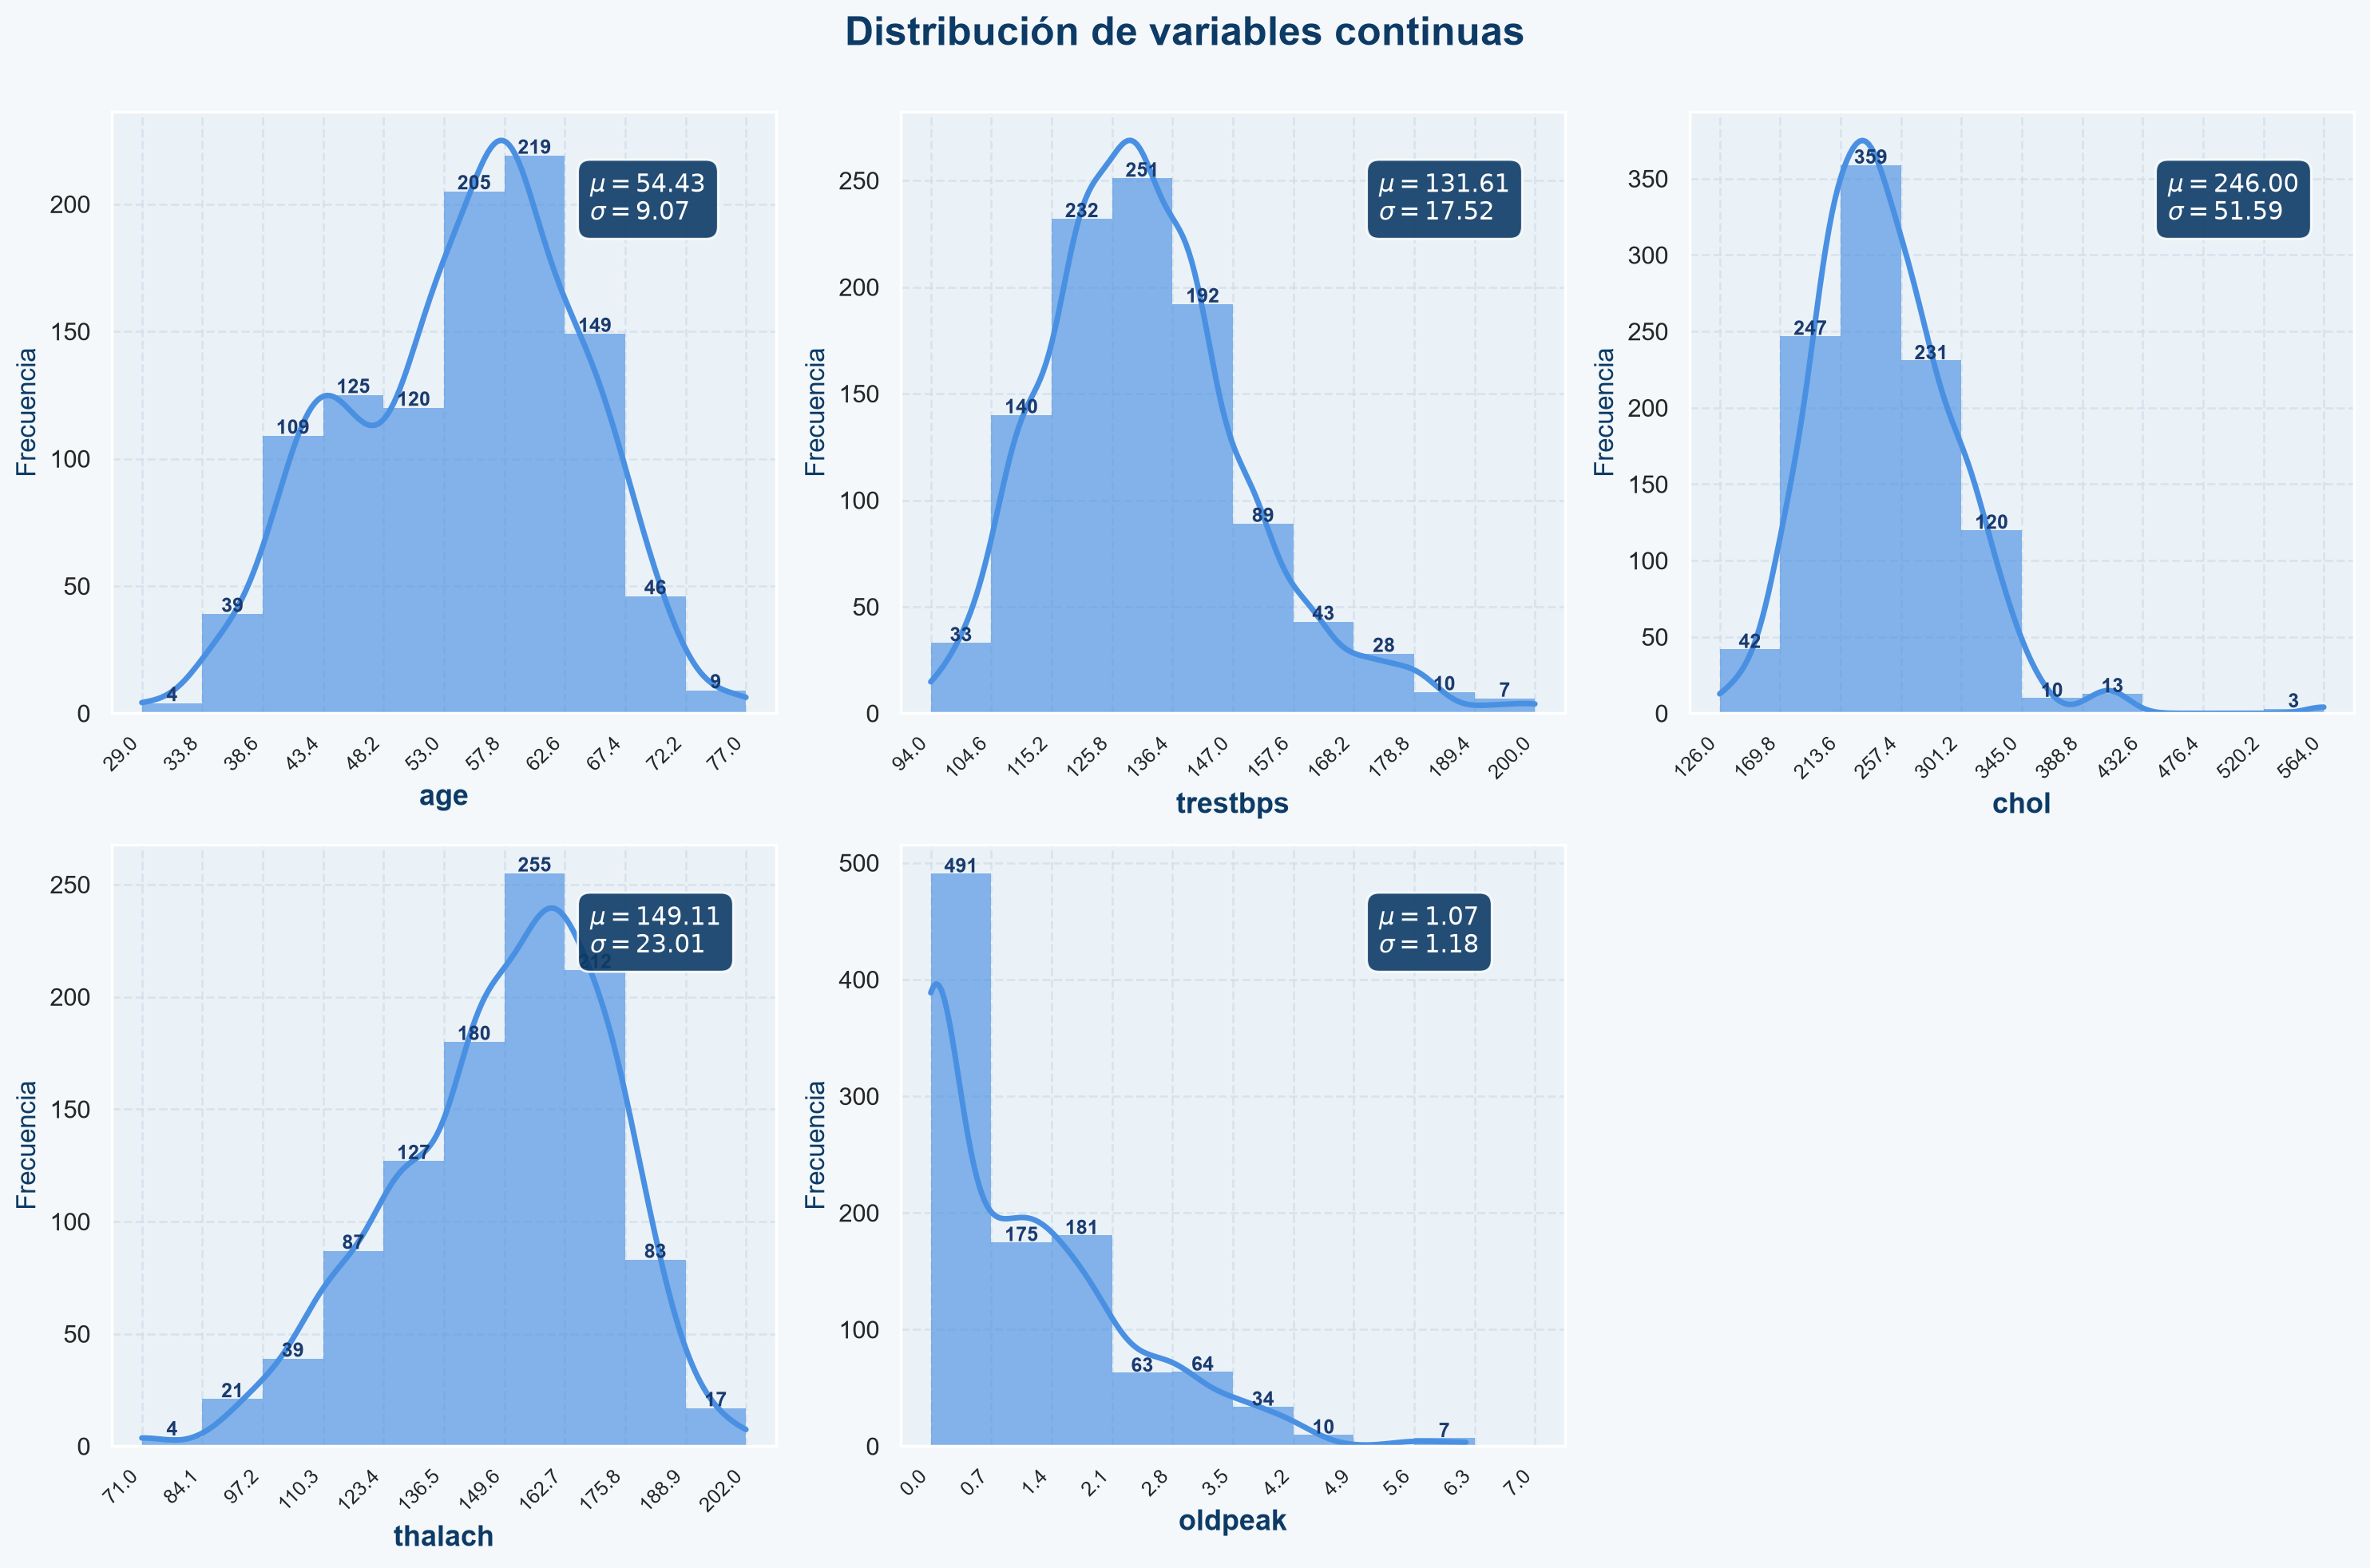

In [8]:
# Filtrar características continuas para el análisis univariado
df_continuas = df[caracteristicas_continuas]

# Configurar la cuadrícula de subgráficos
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))

# Iterar para graficar histogramas de cada característica continua
for i, col in enumerate(df_continuas.columns):
    x = i // 3
    y = i % 3
    valores, bordes_bins = np.histogram(
        df_continuas[col], 
        range=(np.floor(df_continuas[col].min()), np.ceil(df_continuas[col].max()))
    )
    
    # Gráfico con azul clínico intermedio (#4A90E2) y línea KDE en azul marino profundo (#0D3B66)
    grafico = sns.histplot(
        data=df_continuas, 
        x=col, 
        bins=bordes_bins, 
        kde=True, 
        ax=ax[x, y],
        edgecolor='none', 
        color='#4A90E2', 
        alpha=0.65, 
        line_kws={'lw': 2.5, 'color': '#0D3B66'}
    )
    
    ax[x, y].set_facecolor('#EBF2F7')
    ax[x, y].set_xlabel(col, fontsize=13, fontweight='bold', color='#0D3B66')
    ax[x, y].set_ylabel('Frecuencia', fontsize=12, color='#0D3B66')
    ax[x, y].set_xticks(np.round(bordes_bins, 1))
    ax[x, y].set_xticklabels(ax[x, y].get_xticks(), rotation=45, ha='right', fontsize=9)
    ax[x, y].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Anotaciones de frecuencia sobre cada barra
    for j, p in enumerate(grafico.patches):
        altura = p.get_height()
        if altura > 0:
            ax[x, y].annotate(
                f'{int(altura)}', 
                (p.get_x() + p.get_width() / 2, altura + 0.8),
                ha='center', 
                fontsize=9, 
                fontweight='bold',
                color='#1B3B6F'
            )
    
    # Cuadro de estadísticas (media y desviación estándar) en tono azul marino clínico
    texto_estadisticas = '\n'.join((
        r'$\mu=%.2f$' % df_continuas[col].mean(),
        r'$\sigma=%.2f$' % df_continuas[col].std()
    ))
    ax[x, y].text(
        0.72, 0.90, 
        texto_estadisticas, 
        transform=ax[x, y].transAxes, 
        fontsize=11, 
        verticalalignment='top',
        color='white', 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#0D3B66', edgecolor='white', alpha=0.9)
    )

# Desactivar el último eje vacío
ax[1, 2].axis('off')

fig.patch.set_facecolor('#F4F8FA')
plt.suptitle('Distribución de variables continuas', fontsize=18, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

**Observaciones:**
- **Edad (`age`):** La distribución es moderadamente uniforme, aunque presenta una mayor concentración hacia finales de los 50 años. La edad media es de aproximadamente 54.43 años, con una desviación estándar de 9.07 años.
- **Presión arterial en reposo (`trestbps`):** Para la mayoría de los individuos, los valores se concentran entre 120 y 140 mm Hg, con un promedio de cerca de 131.61 mm Hg y una desviación estándar de 17.52 mm Hg.
- **Colesterol sérico (`chol`):** La mayoría de los pacientes registra niveles de colesterol situados entre 200 y 300 mg/dl. El promedio alcanza alrededor de 246.00 mg/dl, con una desviación estándar de 51.59 mg/dl.
- **Frecuencia cardíaca máxima alcanzada (`thalach`):** Gran parte de los individuos alcanza frecuencias de entre 140 y 170 lpm durante la prueba de esfuerzo. El valor promedio se sitúa en torno a 149.11 lpm, con una desviación estándar de 23.01 lpm.
- **Depresión del ST inducida por esfuerzo (`oldpeak`):** La mayoría de los valores se concentra cerca de 0, lo que evidencia que un número significativo de pacientes no experimentó una depresión marcada del segmento ST durante la prueba de ejercicio. El valor promedio es de 1.07, con una desviación estándar de 1.18.

Los histogramas muestran distribuciones consistentes con las referencias clínicas y dentro de los rangos fisiológicos esperados. No se observan anomalías importantes, ruido evidente ni valores inverosímiles.

#### **Análisis univariado de variables categóricas**

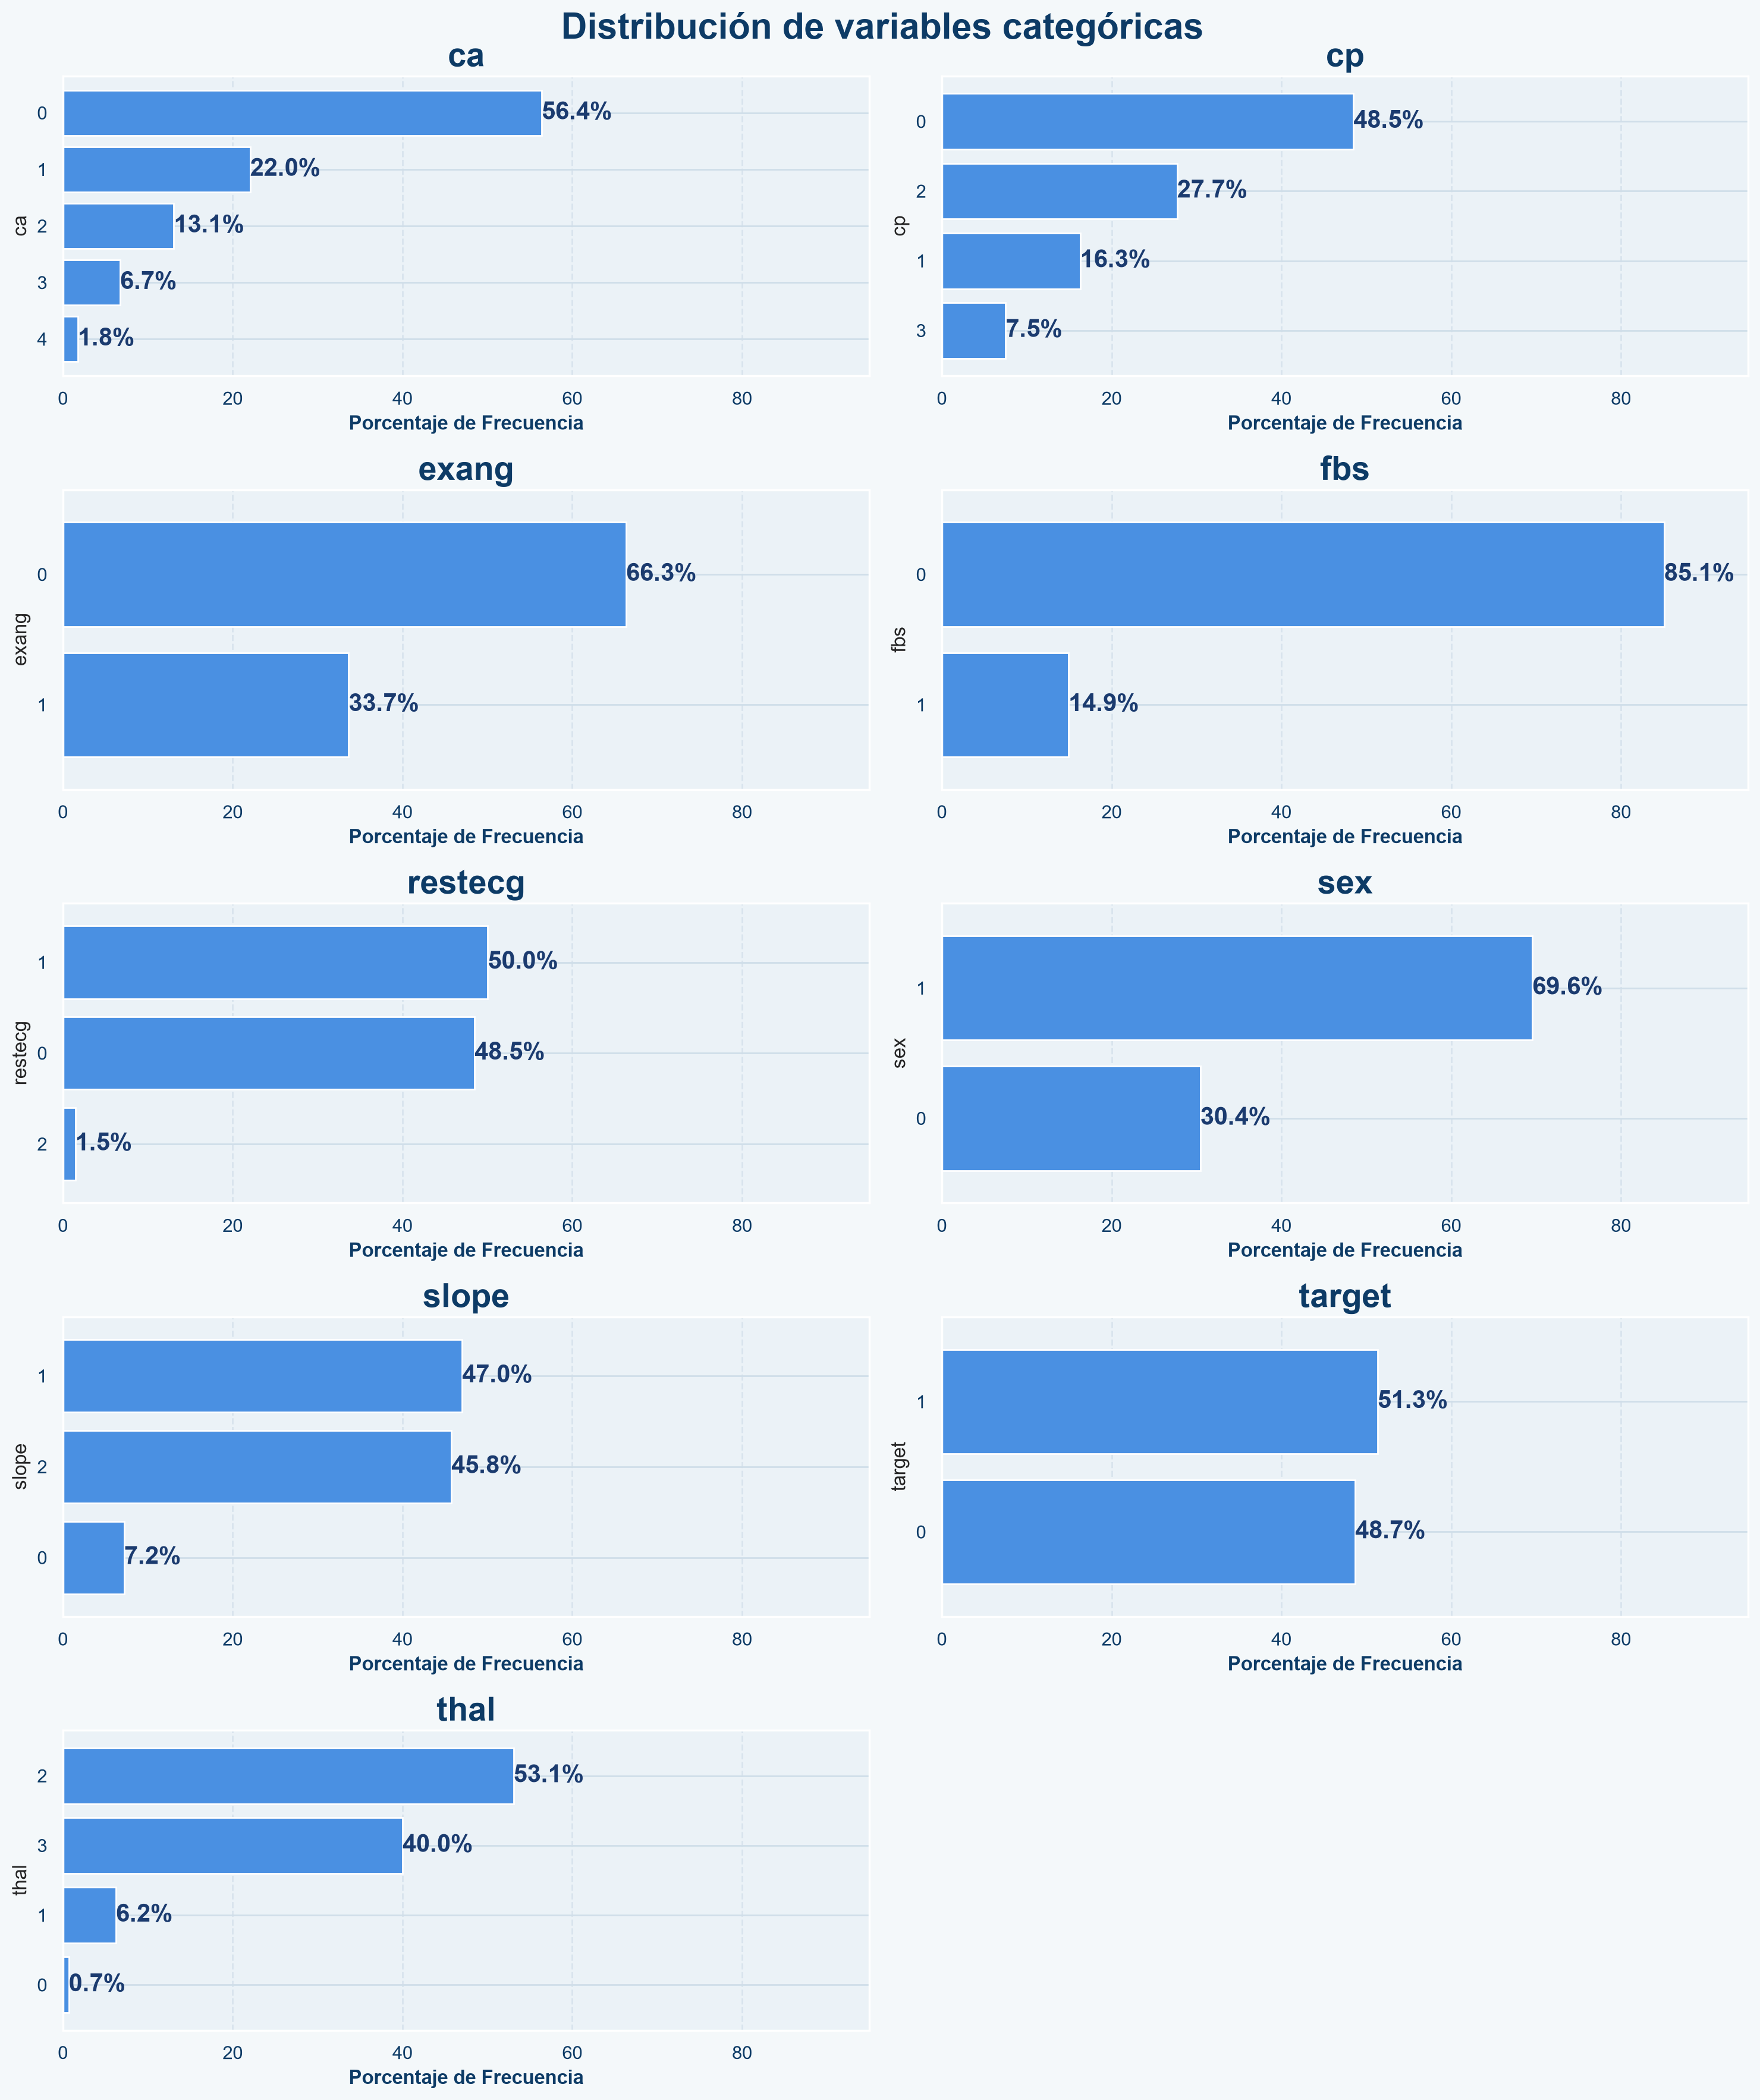

In [9]:
# Filtrar características categóricas para el análisis univariado
caracteristicas_categoricas = df.columns.difference(caracteristicas_continuas)
df_categoricas = df[caracteristicas_categoricas]

# Configurar la cuadrícula de subgráficos para un diseño de 5x2
fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(15, 18))

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

# Iterar para graficar gráficos de barras horizontales para cada característica categórica
for i, col in enumerate(caracteristicas_categoricas):
    row = i // 2
    col_idx = i % 2
    
    # Calcular porcentajes de frecuencia
    conteo_valores = df[col].value_counts(normalize=True).mul(100).sort_values()
    
    # Graficar gráfico de barras usando el color azul clínico intermedio (#4A90E2)
    conteo_valores.plot(kind='barh', ax=ax[row, col_idx], width=0.8, color='#4A90E2')
    
    # Configurar color de fondo del gráfico y la cuadrícula
    ax[row, col_idx].set_facecolor('#EBF2F7')
    ax[row, col_idx].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='x')
    
    # Añadir porcentajes de frecuencia a las barras con el color de texto respectivo (#1B3B6F)
    for index, value in enumerate(conteo_valores):
        ax[row, col_idx].text(
            value, index, str(round(value, 1)) + '%', 
            fontsize=15, weight='bold', va='center', color='#1B3B6F'
        )
    
    # Configuración de los ejes y títulos usando azul marino profundo (#0D3B66)
    ax[row, col_idx].set_xlim([0, 95])
    ax[row, col_idx].set_xlabel('Porcentaje de Frecuencia', fontsize=12, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].set_title(f'{col}', fontsize=20, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].tick_params(colors='#0D3B66')

# Desactivar el último eje vacío
ax[4, 1].axis('off')

# Título principal de la figura
plt.suptitle('Distribución de variables categóricas', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

**Observaciones**:
- **Género** (`sex`): Predominan las pacientes de género masculino, constituyendo una mayoría significativa.
- **Tipo de dolor en el pecho** (`cp`): Se observan distintos tipos de dolor en el pecho entre los pacientes, siendo el tipo 0 (angina típica) el más frecuente.
- **Azúcar en sangre en ayunas** (`fbs`): La mayoría de los pacientes presenta su nivel de azúcar en sangre en ayunas inferiores a 120 mg/dl.
- **Resultados electrocardiográficos en reposo** (`restecg`): Se observan distintos resultados, aunque algunas categorías son más frecuentes que otras.
- **Angina inducida por el ejercicio** (`exang`): La mayoría de los pacientes no presenta angina durante el ejercicio, lo que sugiere que podría no ser un síntoma común entre los pacientes.
- **Pendiente del segmento ST** (`slope`): Se identifican distintas categorías, con predominio de una de ellas.
- **Número de vasos principales coloreados por fluoroscopia** (`ca`): La categoría 0 es la más frecuente, por lo que la mayoría presenta menos vasos coloreados por fluoroscopia.
- **Resultado de la prueba de esfuerzo con talio** (`thal`): Se observan distintos resultados, con predominio de una categoría.
- **Presencia de enfermedad cardíaca** (`target`): El conjunto está relativamente equilibrado: el 51,3 % presenta enfermedad cardíaca y el 48,7 % no.

### **2.3.2 Análisis Bivariado**

Para el análisis bivariado de las características respecto a la variable objetivo (`target`), se utilizarán las siguientes visualizaciones:

- **Datos continuos:** Se emplearán gráficos de barras para comparar los promedios de cada característica entre ambas clases y gráficos KDE para observar sus distribuciones.
- **Datos categóricos:** Se utilizarán gráficos de barras apiladas al 100 % para comparar la proporción de cada categoría según la clase objetivo.

Estas visualizaciones permitirán identificar patrones y diferencias entre ambas clases, así como posibles variables relacionadas con la presencia de enfermedad cardíaca.

#### **Características numéricas vs. Objetivo**

Se visualizará cada característica continua frente a la variable objetivo utilizando dos tipos de gráficos:
- **Gráficos de barras** que muestran los valores promedio.
- **Gráficos KDE** que muestran la distribución para cada categoría de la variable objetivo.

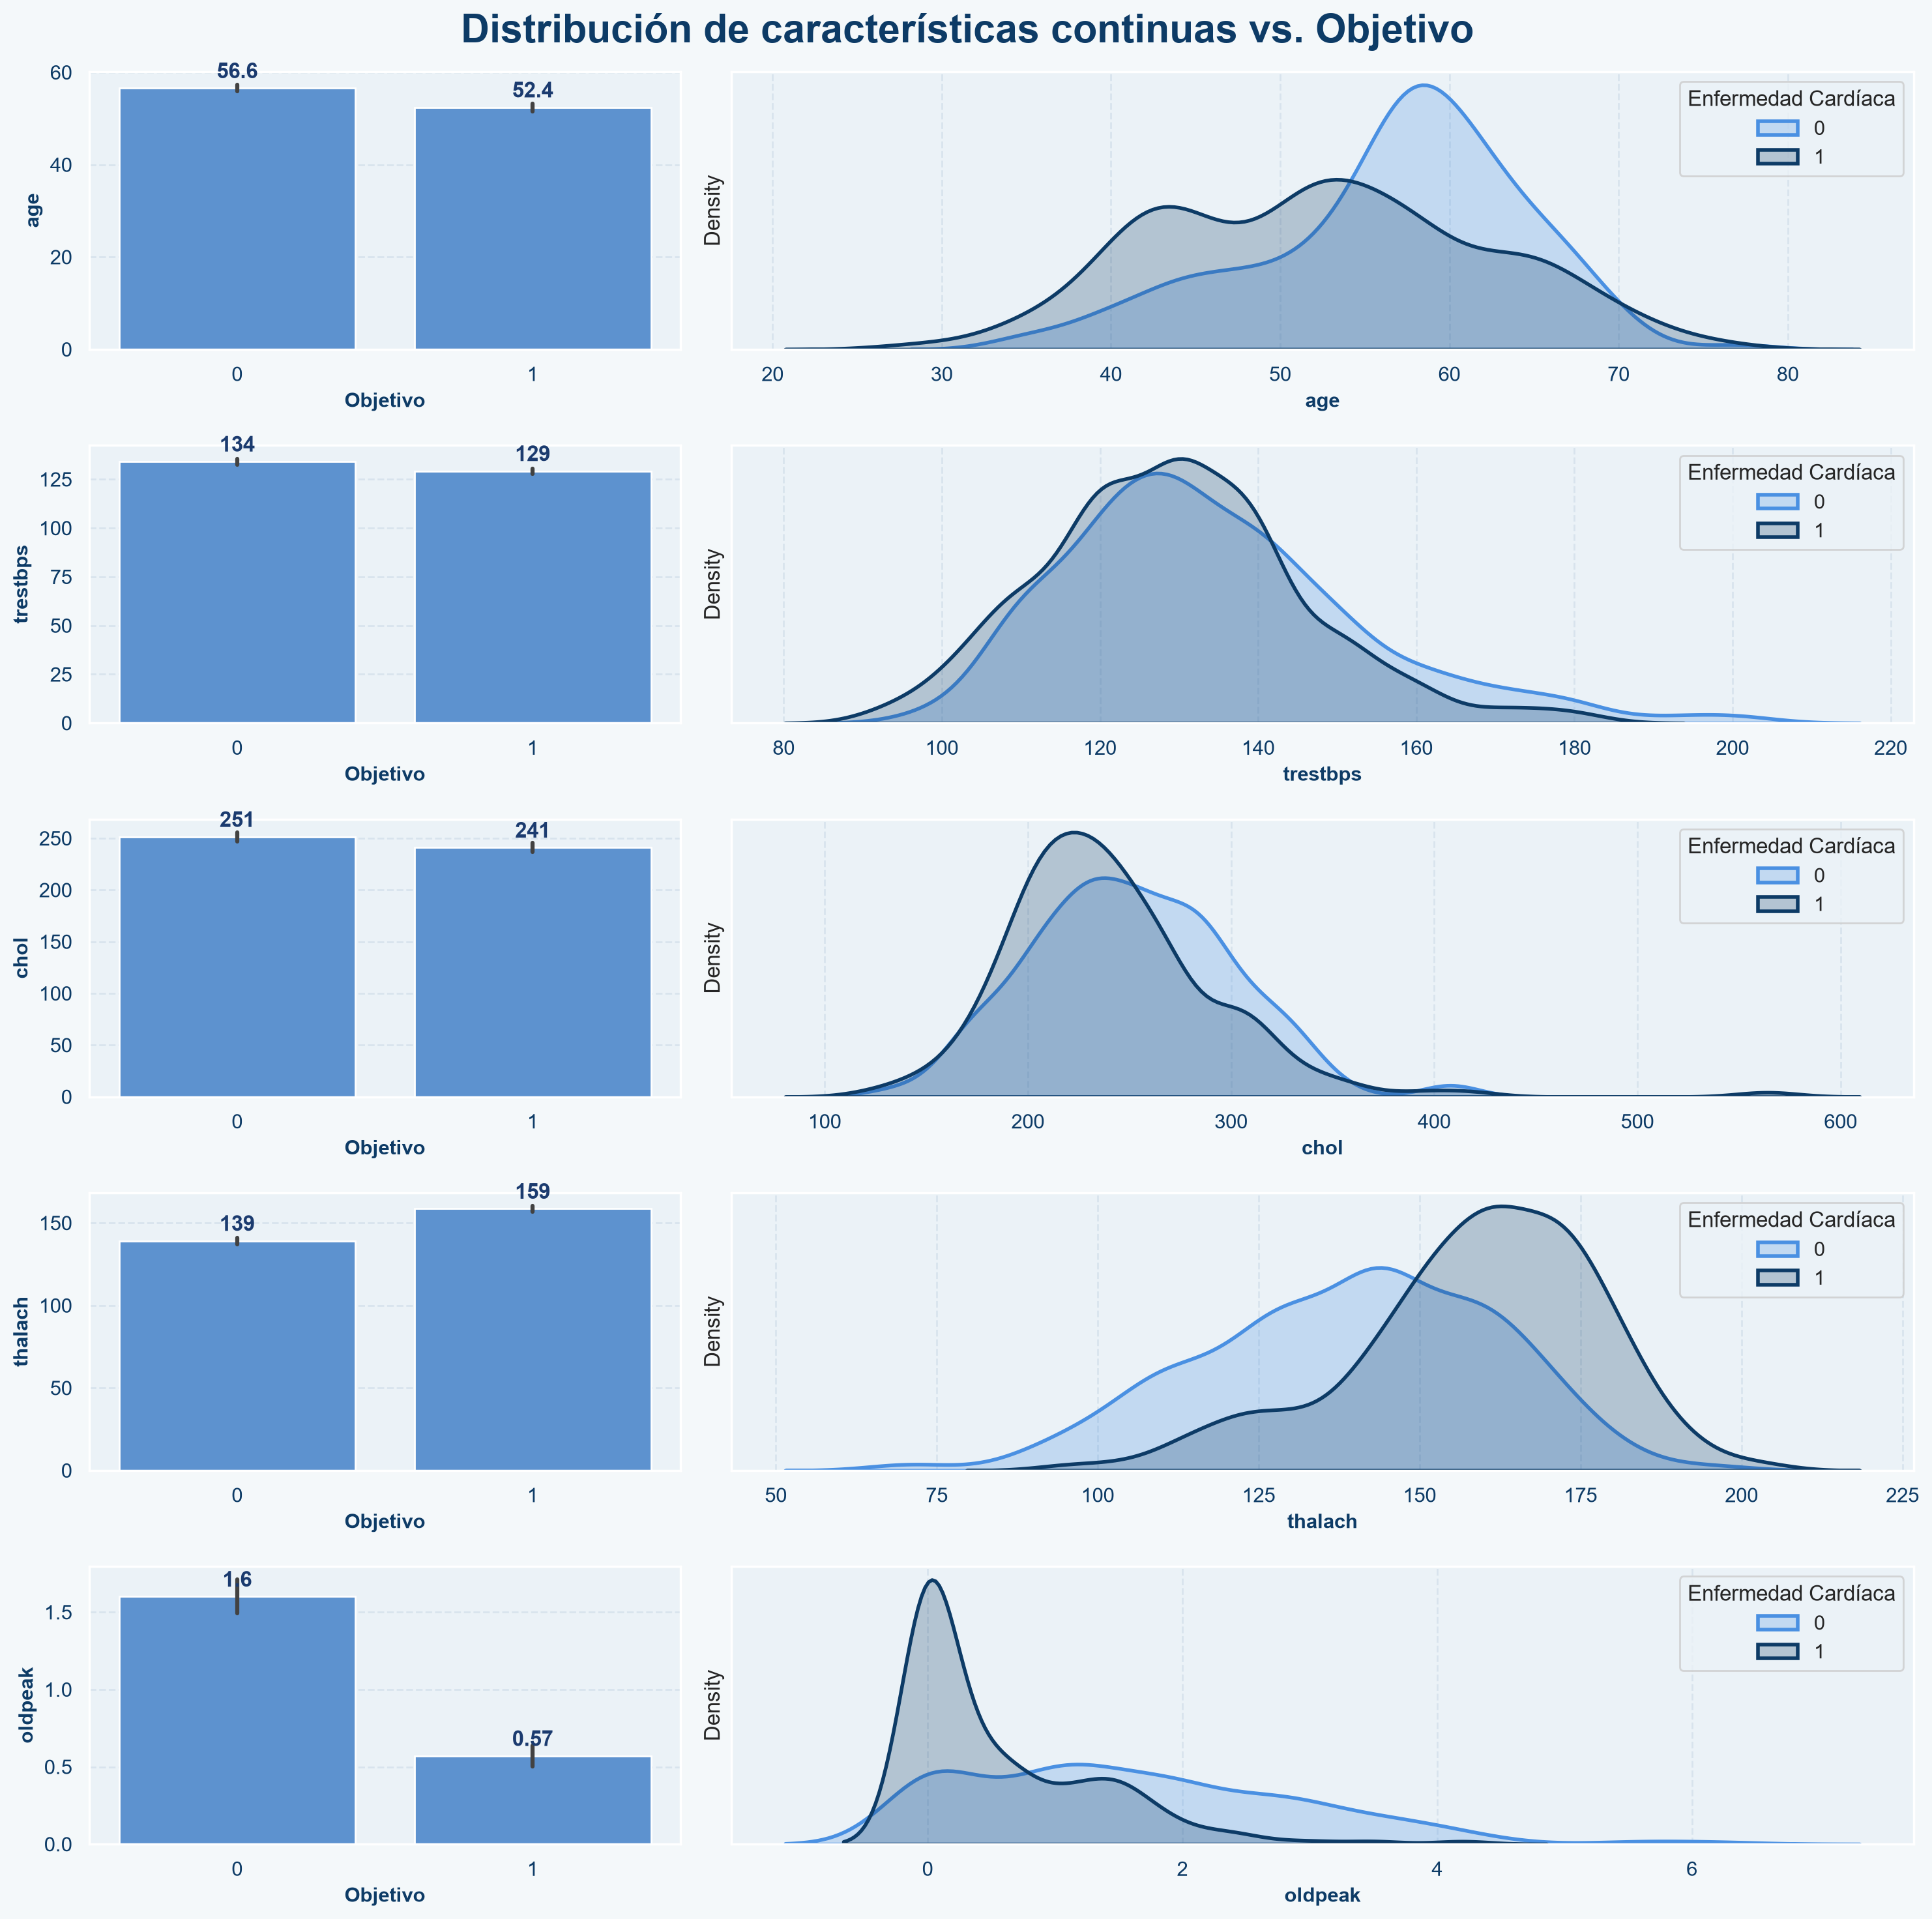

In [10]:
sns.set_palette(['#4A90E2', '#0D3B66'])

# Crear los subgráficos
fig, ax = plt.subplots(len(caracteristicas_continuas), 2, figsize=(15, 15), gridspec_kw={'width_ratios': [1, 2]})

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

# Iterar a través de cada característica continua para crear gráficos de barras y gráficos KDE
for i, col in enumerate(caracteristicas_continuas):
    # Gráfico de barras que muestra el valor promedio de la característica para cada categoría objetivo
    grafico = sns.barplot(data=df, x="target", y=col, ax=ax[i, 0])
    
    # Gráfico KDE que muestra la distribución de la característica para cada categoría objetivo
    sns.kdeplot(data=df[df["target"] == 0], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='0')
    sns.kdeplot(data=df[df["target"] == 1], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='1')
    
    # Configurar colores de fondo para los ejes
    ax[i, 0].set_facecolor('#EBF2F7')
    ax[i, 1].set_facecolor('#EBF2F7')
    
    # Configurar cuadrícula
    ax[i, 0].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='y')
    ax[i, 1].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Estilizar etiquetas de ejes
    ax[i, 0].set_xlabel('Objetivo', fontsize=11, fontweight='bold', color='#0D3B66')
    ax[i, 0].set_ylabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    ax[i, 1].set_xlabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    
    # Ocultar ticks en el eje Y para el KDE, pero mantener el color en el eje X
    ax[i, 1].set_yticks([])
    ax[i, 0].tick_params(colors='#0D3B66')
    ax[i, 1].tick_params(colors='#0D3B66')
    
    # Configurar la leyenda
    ax[i, 1].legend(title='Enfermedad Cardíaca', loc='upper right')
    
    # Añadir valores promedio al gráfico de barras
    for cont in grafico.containers:
        grafico.bar_label(cont, fmt='%.3g', color='#1B3B6F', fontweight='bold', padding=3)

# Establecer el título para toda la figura
plt.suptitle('Distribución de características continuas vs. Objetivo', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

**Observaciones:**
- **Edad** (`age`): Los pacientes con enfermedad cardíaca son, en promedio, ligeramente más jóvenes que aquellos sin ella.
- **Presión arterial en reposo** (`trestbps`): Ambas clases presentan distribuciones similares y promedios casi idénticos, por lo que esta variable muestra poca capacidad de diferenciación.
- **Colesterol sérico** (`chol`): Las distribuciones son similares, aunque los pacientes con enfermedad cardíaca presentan un promedio ligeramente menor.
- **Frecuencia cardíaca máxima** (`thalach`): Los pacientes con enfermedad cardíaca tienden a alcanzar una frecuencia cardíaca máxima más alta durante las pruebas de esfuerzo en comparación con aquellos que no la padecen.
- **Depresión del segmento ST** (`oldpeak`): Los pacientes con enfermedad cardíaca presentan valores generalmente menores, concentrados cerca de cero, mientras que aquellos sin ella muestran mayor dispersión.

Basándose en la diferencia visual de las distribuciones y los valores promedio, la **Frecuencia cardíaca máxima (`thalach`)** parece tener el mayor impacto sobre la presencia de enfermedad cardíaca, seguida por la **Depresión del segmento ST (`oldpeak`)** y la **Edad (`age`)**.

#### **Características categóricas vs. Objetivo**

Se mostrarán gráficos de barras apiladas al 100% para cada característica categórica, ilustrando la proporción de cada categoría en las dos clases objetivo, complementados con los conteos exactos y porcentajes en las barras.

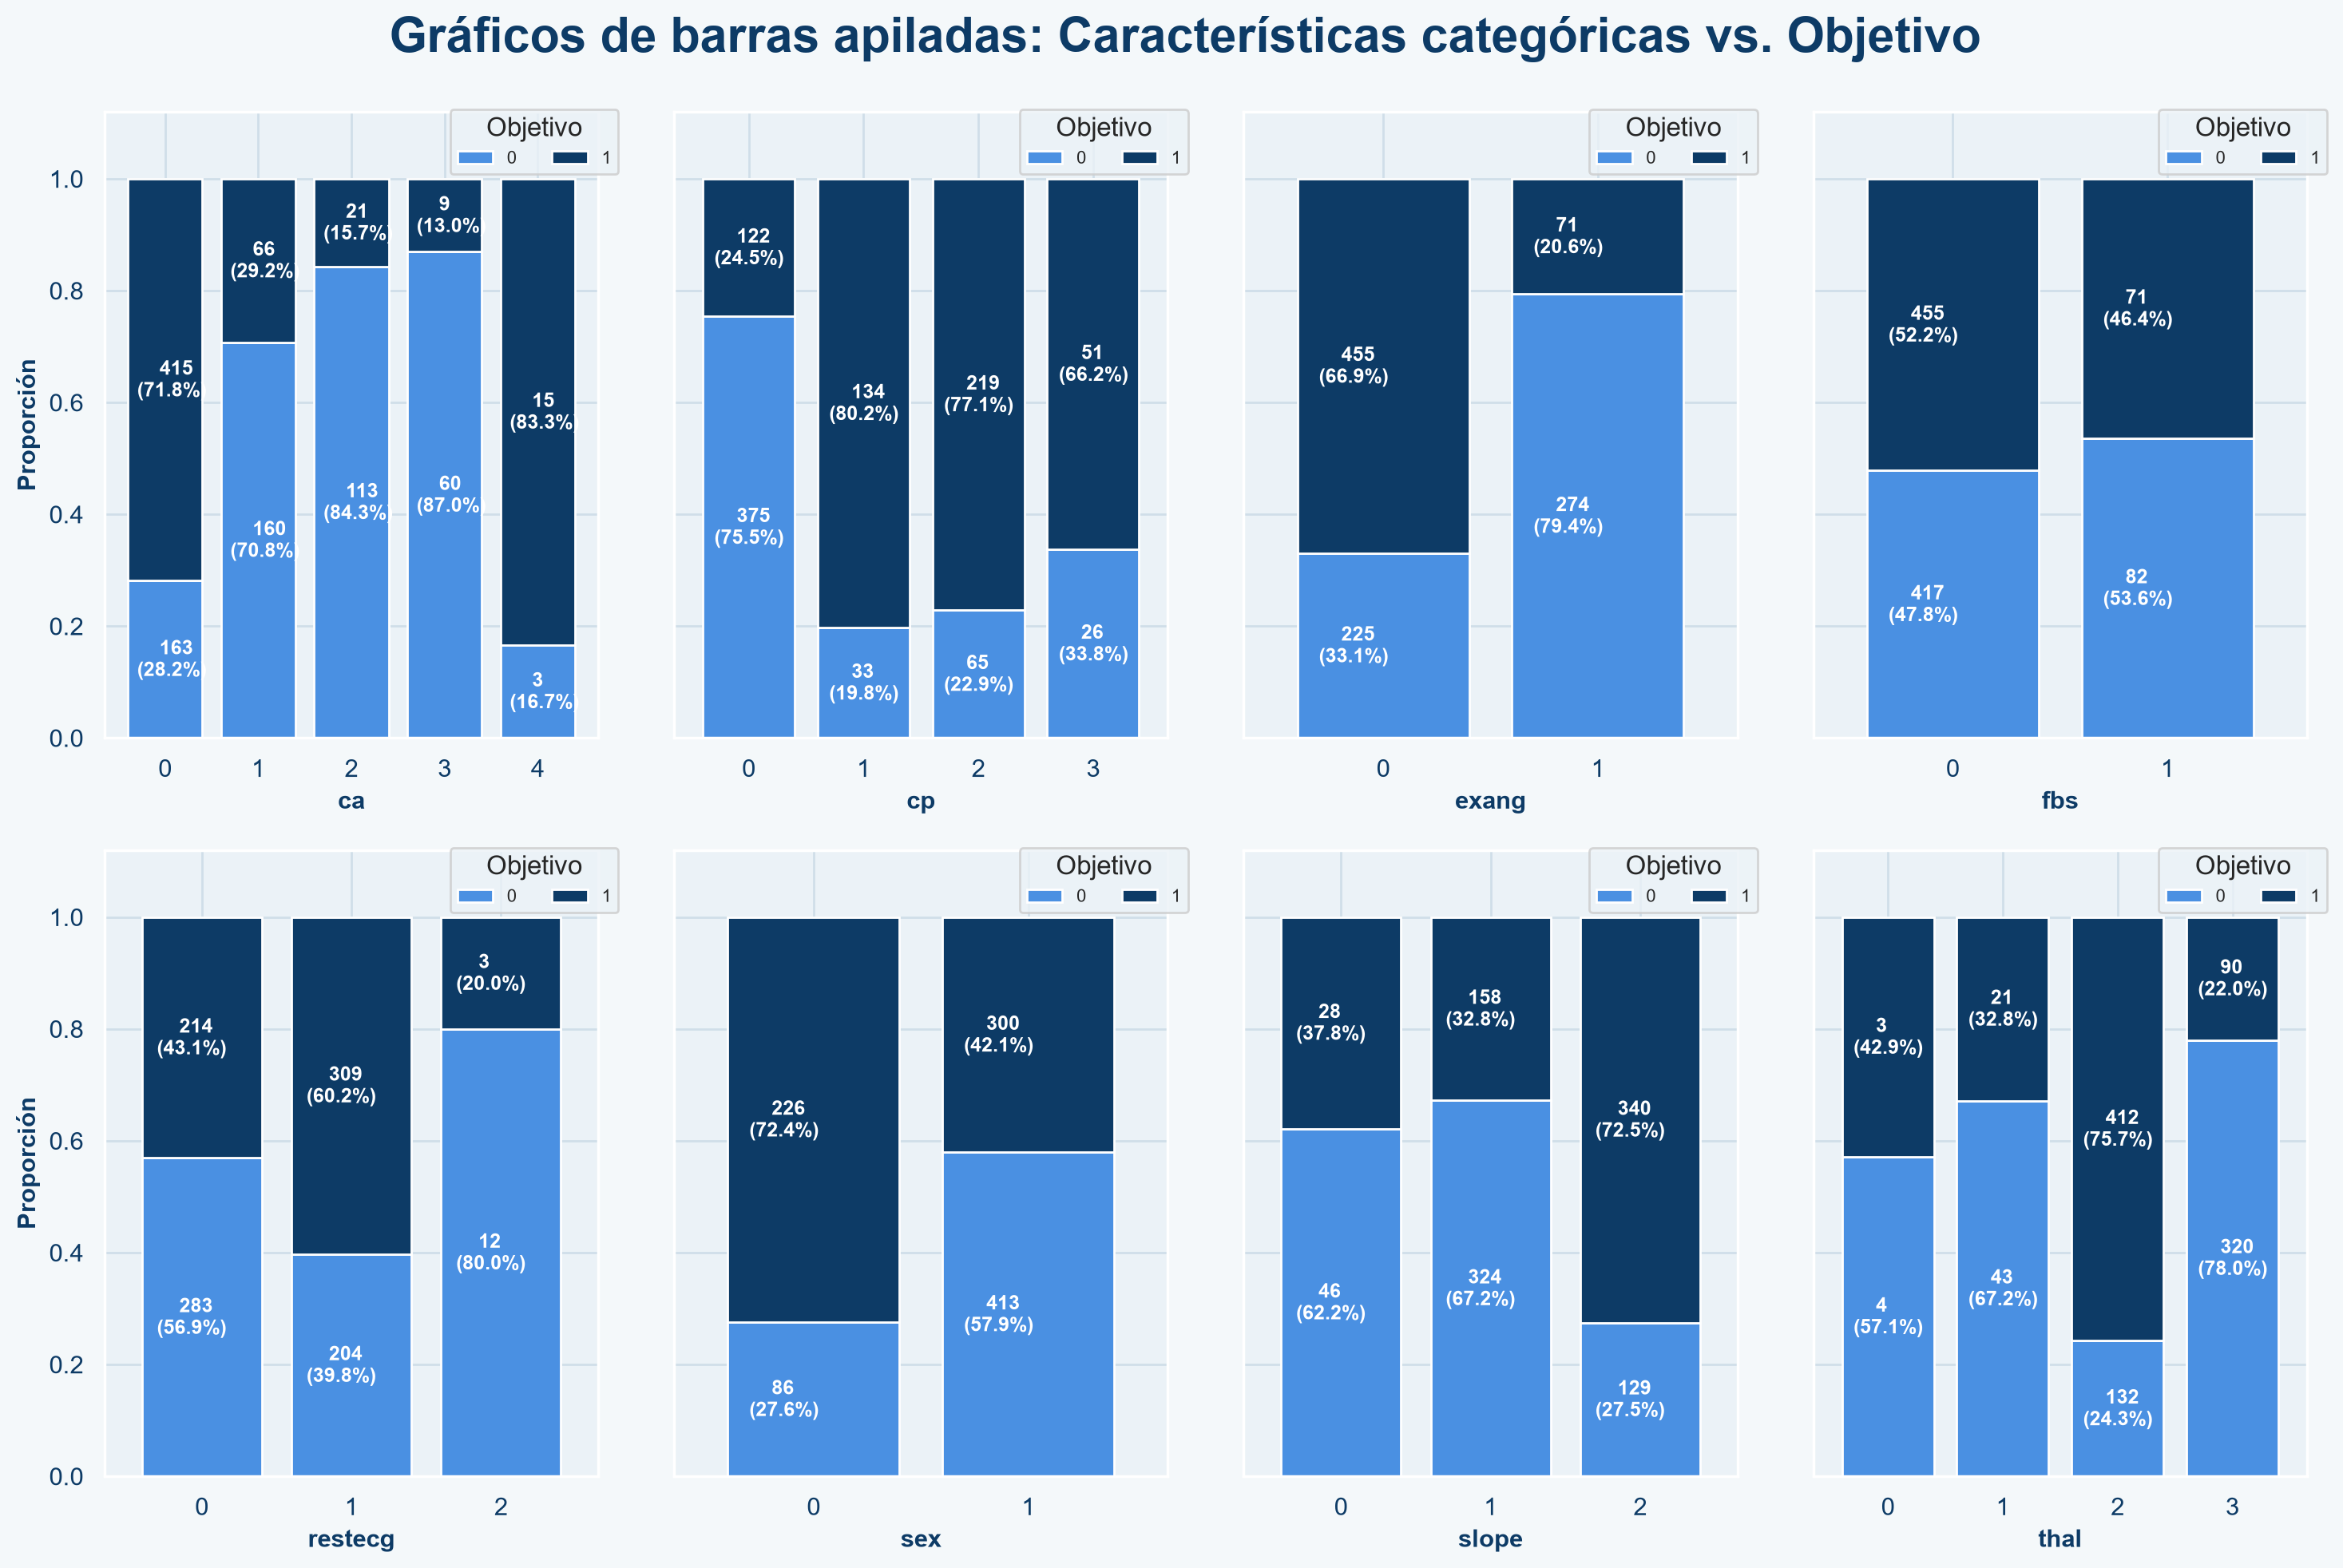

In [11]:
# Eliminar 'target' de las caracteristicas_categoricas
caracteristicas_categoricas = [caracteristica for caracteristica in caracteristicas_categoricas if caracteristica != 'target']

fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(15, 10))

# Aplicar color de fondo a la figura completa
fig.patch.set_facecolor('#F4F8FA')

for i, col in enumerate(caracteristicas_categoricas):
    
    # Crear una tabla cruzada que muestre la proporción de cada categoría de la característica con respecto al objetivo
    tabla_cruzada = pd.crosstab(index=df[col], columns=df['target'])
    
    # Usar el argumento normalize='index' nos da la proporción de los datos por índice
    tabla_cruzada_prop = pd.crosstab(index=df[col], columns=df['target'], normalize='index')

    # Definir mapa de colores con la paleta clínica (azul clínico intermedio y azul marino profundo)
    cmp = ListedColormap(['#4A90E2', '#0D3B66'])
    
    # Graficar gráficos de barras apiladas
    x, y = i // 4, i % 4
    tabla_cruzada_prop.plot(kind='bar', ax=ax[x, y], stacked=True, width=0.8, colormap=cmp,
                            legend=False, ylabel='Proporción', sharey=True)
    
    # Configurar colores de fondo y estilo de ejes
    ax[x, y].set_facecolor('#EBF2F7')
    ax[x, y].set_xlabel(col, fontsize=11, fontweight='bold', color='#0D3B66')
    ax[x, y].tick_params(colors='#0D3B66')
    
    if y == 0:
        ax[x, y].set_ylabel('Proporción', fontsize=11, fontweight='bold', color='#0D3B66')
    else:
        ax[x, y].set_ylabel('')

    # Añadir las proporciones y conteos de las barras individuales a nuestro gráfico
    for idx, val in enumerate([*tabla_cruzada.index.values]):
        for (proporcion, conteo, y_location) in zip(tabla_cruzada_prop.loc[val], tabla_cruzada.loc[val], tabla_cruzada_prop.loc[val].cumsum()):
            # Se utiliza texto blanco para un mejor contraste sobre los tonos azules
            ax[x, y].text(x=idx - 0.3, y=(y_location - proporcion) + (proporcion / 2) - 0.03,
                         s=f'    {conteo}\n({np.round(proporcion * 100, 1)}%)', 
                         color="white", fontsize=9, fontweight="bold")
    
    # Añadir leyenda
    ax[x, y].legend(title='Objetivo', loc=(0.7, 0.9), fontsize=8, ncol=2)
    # Establecer límite del eje y
    ax[x, y].set_ylim([0, 1.12])
    # Rotar etiquetas del eje x
    ax[x, y].set_xticklabels(ax[x, y].get_xticklabels(), rotation=0)

# Títulos y ajustes finales de la figura
plt.suptitle('Gráficos de barras apiladas: Características categóricas vs. Objetivo', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.92) # Ajuste adicional para que el título principal no se superponga
plt.show()

**Observaciones:**
- **Número de vasos principales** (`ca`): La mayor proporción de enfermedad cardíaca se presenta en pacientes con 0 vasos coloreados. Esta proporción tiende a disminuir a medida que aumenta su número.
- **Tipo de dolor en el pecho** (`cp`): Las categorías 1, 2 y 3 presentan una mayor proporción de enfermedad cardíaca que la categoría 0, lo que sugiere su relevancia para la predicción.
- **Angina inducida por el ejercicio** (`exang`): Los pacientes sin angina (0) presentan una mayor proporción de enfermedad cardíaca que aquellos con angina (1). Esta variable muestra una relación importante con el objetivo.
- **Azúcar en sangre en ayunas** (`fbs`): Ambas categorías presentan proporciones similares de enfermedad cardíaca, por lo que esta variable parece tener una influencia limitada en la predicción.
- **Resultados electrocardiográficos en reposo** (`restecg`): La categoría 1 presenta una mayor proporción de enfermedad cardíaca, lo que sugiere cierta relación con el objetivo.
- **Sexo** (`sex`): Los hombres (1) presentan una menor proporción de enfermedad cardíaca que las mujeres (0), lo que sugiere que esta variable puede ser relevante para la predicción.
- **Pendiente del segmento ST** (`slope`): La categoría 2 presenta una proporción notablemente mayor de enfermedad cardíaca, lo que sugiere su posible relevancia como predictor.
- **Resultado de la prueba de esfuerzo con talio** (`thal`): La categoría 2 (defecto reversible) presenta una mayor proporción de enfermedad cardíaca que las demás categorías, destacando su posible relevancia para la predicción.

En resumen, basándose en la representación visual:
* **Mayor impacto en el objetivo:** `ca`, `cp`, `exang`, `sex`, `slope` y `thal`.
* **Impacto moderado en el objetivo:** `restecg`.
* **Menor impacto en el objetivo:** `fbs`.

# **3. Preparación de los Datos para Machine Learning**

## **3.1 Eliminación de características irrelevantes**

Todas las características del conjunto de datos parecen ser relevantes basándose en el Análisis Exploratorio de Datos (EDA). Ninguna columna parece ser redundante o irrelevante. Por lo tanto, se conservarán todas las características, asegurando que no se pierda información valiosa, especialmente considerando el pequeño tamaño del conjunto de datos.

## **3.2 Tratamiento de valores nulos**

In [12]:
# Comprobar si hay valores nulos en el conjunto de datos
df.isnull().sum().sum()

np.int64(0)

Tras la inspección anterior, es evidente que no hay valores nulos en el conjunto de datos. Esto es ideal, ya que significa que no se deben tomar decisiones sobre imputación o eliminación, lo cual podría introducir sesgos o reducir aún más el limitado tamaño del conjunto de datos.

## **3.3 Tratamiento de valores atípicos (outliers)**

Se comprobará la existencia de valores atípicos utilizando el método del rango intercuartílico (IQR) para las características continuas:

In [13]:
caracteristicas_continuas

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [14]:
Q1 = df[caracteristicas_continuas].quantile(0.25)
Q3 = df[caracteristicas_continuas].quantile(0.75)
IQR = Q3 - Q1
conteo_atipicos_especificados = ((df[caracteristicas_continuas] < (Q1 - 1.5 * IQR)) | (df[caracteristicas_continuas] > (Q3 + 1.5 * IQR))).sum()
conteo_atipicos_especificados

age          0
trestbps    30
chol        16
thalach      4
oldpeak      7
dtype: int64

Al identificar los valores atípicos para las características continuas especificadas, se encontró lo siguiente:

- `trestbps`: 30 valores atípicos
- `chol`: 16 valores atípicos
- `thalach`: 4 valores atípicos
- `oldpeak`: 7 valores atípicos
- `age`: Sin valores atípicos

Sensibilidad a los valores atípicos: Los **Árboles de Decisión** y **Random Forest** suelen ser robustos frente a valores extremos, ya que realizan divisiones según los valores de las características. Por ello, los valores atípicos suelen quedar en nodos hoja y tener un impacto limitado en las decisiones del modelo.

##### **Tratamiento de Valores Atípicos**

In [38]:
# Obtener los valores identificados como atípicos
mascara_atipicos = (
    (df[caracteristicas_continuas] < (Q1 - 1.5 * IQR)) |
    (df[caracteristicas_continuas] > (Q3 + 1.5 * IQR))
)

for columna in caracteristicas_continuas:
    valores = df.loc[mascara_atipicos[columna], columna].sort_values()
    print(f'{columna}: {valores.tolist()}')

age: []
trestbps: [172, 172, 172, 174, 174, 174, 178, 178, 178, 178, 178, 178, 178, 180, 180, 180, 180, 180, 180, 180, 180, 180, 180, 192, 192, 192, 200, 200, 200, 200]
chol: [394, 394, 394, 407, 407, 407, 407, 409, 409, 409, 417, 417, 417, 564, 564, 564]
thalach: [71, 71, 71, 71]
oldpeak: [5.6, 5.6, 5.6, 5.6, 6.2, 6.2, 6.2]


Los valores identificados mediante el método IQR fueron revisados considerando sus magnitudes y el contexto de cada característica. Se comprobó que corresponden a valores extremos, pero plausibles, y no se identificaron evidencias suficientes para considerarlos errores de registro. Por lo tanto, se conservarán sin aplicar técnicas de eliminación o modificación.

## **3.4 Tratamiento de registros duplicados**

Se comprobará la existencia de registros duplicados en el conjunto de datos utilizando el método `duplicated()` de Pandas, que permite identificar observaciones cuyos valores coinciden en todas sus columnas.

In [15]:
# Contar registros duplicados
duplicados = df.duplicated().sum()

# Calcular porcentaje de registros duplicados
porcentaje_duplicados = (duplicados / len(df)) * 100

print(f"Registros duplicados: {duplicados}")
print(f"Porcentaje de duplicados: {porcentaje_duplicados:.2f}%")

Registros duplicados: 723
Porcentaje de duplicados: 70.54%


**Consideraciones sobre los registros duplicados:**

La presencia de registros con valores idénticos no significa necesariamente que correspondan al mismo paciente. Dado que el conjunto de datos no cuenta con identificadores únicos, no es posible determinar si estas coincidencias representan registros repetidos de una misma persona o pacientes diferentes que presentan exactamente las mismas características clínicas.

**Conclusión:**

Considerando la falta de identificadores que permitan distinguir a los pacientes, se ha decidido **mantener los registros duplicados** en el conjunto de datos. Eliminarlos podría significar descartar observaciones correspondientes a personas diferentes que, por coincidencia, presentan características clínicas idénticas. Por lo tanto, se conservará el conjunto de datos completo, evitando eliminar información sin tener certeza de que se trata de registros repetidos de un mismo paciente.

## **3.5 Codificación de características categóricas**

**Decisión sobre la codificación One-Hot:**

Con base en las características de las variables, se evaluará la aplicación de codificación One-Hot Encoding según su naturaleza:

1. **Variables nominales:** No tienen un orden definido. Se recomienda aplicar One-Hot Encoding para evitar que el modelo interprete una jerarquía inexistente.
2. **Variables ordinales:** Tienen un orden inherente, por lo que pueden representarse mediante valores numéricos sin perder esa información.

Según estos criterios:

- `sex`: Variable binaria (masculino y femenino). No requiere One-Hot Encoding.
- `cp`: Variable nominal que representa distintos tipos de dolor torácico sin un orden definido. Se aplicará One-Hot Encoding.
- `fbs`: Variable binaria (verdadero o falso). No requiere One-Hot Encoding.
- `restecg`: Representa distintos resultados electrocardiográficos sin un orden definido. Se aplicará One-Hot Encoding.
- `exang`: Variable binaria (presencia o ausencia de angina inducida por ejercicio). No requiere One-Hot Encoding.
- `slope`: Representa la pendiente del segmento ST (ascendente, plana o descendente), por lo que se tratará como ordinal y no se aplicará One-Hot Encoding.
- `ca`: Representa el número de vasos principales coloreados por fluoroscopia. Al ser un conteo con orden inherente, no requiere One-Hot Encoding.
- `thal`: Representa distintos resultados de la prueba de esfuerzo con talio, sin un orden definido. Se aplicará One-Hot Encoding.

**Resumen:**
- **Necesitan codificación One-Hot:** `cp`, `restecg`, `thal`
- **No necesitan codificación One-Hot:** `sex`, `fbs`, `exang`, `slope`, `ca`

In [16]:
# Características que requieren codificación One-Hot
caracteristicas_categoricas = ['cp', 'restecg', 'thal']

# Crear componente de preprocesamiento
preprocesador = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            dtype=int
        ), caracteristicas_categoricas)
    ],
    remainder='passthrough'
)

# Convertir el resto de las variables categóricas que no necesitan codificación one-hot a tipo de dato entero
caracteristicas_a_convertir = ['sex', 'fbs', 'exang', 'slope', 'ca', 'target']
for caracteristica in caracteristicas_a_convertir:
    df[caracteristica] = df[caracteristica].astype(int)

df.dtypes

age           int64
sex           int64
cp           object
trestbps      int64
chol          int64
fbs           int64
restecg      object
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal         object
target        int64
dtype: object

In [17]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


## **3.6 Escalado de características**

El escalado de características ajusta la magnitud de las variables numéricas para que tengan escalas comparables. Su aplicación depende de los algoritmos utilizados.

**Por qué se omite en este momento:**

Los modelos de **Árbol de Decisión** y **Random Forest** realizan divisiones basadas en umbrales y, por lo general, no son sensibles a la escala de las variables. Por lo tanto, no necesitan que las características tengan magnitudes similares.

En consecuencia, **se omitirá el escalado** y se conservarán los valores originales de las variables numéricas.

## **3.7 Prevención de Fuga de Datos (Data Leakage)**

Durante el preprocesamiento y entrenamiento es importante evitar la fuga de datos (*Data Leakage*), que ocurre cuando se utiliza información del conjunto de prueba durante el entrenamiento o el preprocesamiento, lo que puede generar resultados demasiado optimistas y evaluaciones poco fiables.

Para evitarlo, se seguirá el siguiente procedimiento:

1. **División de datos:** Se dividirá el conjunto de datos en entrenamiento y prueba. Este último se mantendrá separado durante el entrenamiento y el ajuste de los modelos.

2. **Preprocesamiento:** Las transformaciones que requieran calcular parámetros a partir de los datos, como la codificación de variables categóricas o la imputación de valores faltantes, se ajustarán únicamente con los datos de entrenamiento y luego se aplicarán al conjunto de prueba.

3. **Validación cruzada y ajuste de hiperparámetros:** Se utilizará validación cruzada sobre el conjunto de entrenamiento para evaluar los modelos y optimizar sus hiperparámetros, sin utilizar información del conjunto de prueba.

4. **Evaluación final:** Una vez seleccionados y ajustados los modelos, se utilizará el conjunto de prueba para evaluar su rendimiento sobre datos que no participaron en el entrenamiento ni en el ajuste de hiperparámetros.

De esta manera, se evita la fuga de información y se obtiene una evaluación más confiable de la capacidad de generalización de los modelos de Árbol de Decisión y Random Forest.

In [18]:
# Definir las características (X) y las etiquetas de salida (y)
X = df.drop('target', axis=1)
y = df['target'] 

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# **4. Construcción de Modelos**

## **4.1 Construcción del modelo de Árbol de Decisión (DT)**

### **Definición del modelo base de Árbol de Decisión**


In [19]:
pipeline_dt = Pipeline([
    ('preprocesador', preprocesador),
    ('clasificador', DecisionTreeClassifier(random_state=42))
])

### **Ajuste de hiperparámetros del Árbol de Decisión**

> **Nota:** En el diagnóstico médico se prioriza una alta sensibilidad (recall) para la clase positiva, ya que permite identificar la mayoría de los pacientes con la enfermedad y reducir los falsos negativos, aunque esto implique algunos falsos positivos. Por ello, se utilizará una función que seleccione los hiperparámetros que maximicen el recall del modelo.

In [20]:
def ajustar_hiperparametros_clf(clasificador, grid_parametros, X_train, y_train, metrica='recall', n_splits=5):    
    '''    
    Esta función optimiza los hiperparámetros para un clasificador buscando en una cuadrícula de hiperparámetros especificada.     
    Utiliza GridSearchCV y validación cruzada (StratifiedKFold) para evaluar diferentes combinaciones de hiperparámetros.     
    La combinación con la mayor sensibilidad (recall) para la clase 1 se selecciona como la métrica de puntuación predeterminada.     
    La función devuelve el clasificador con los hiperparámetros óptimos.    
    '''
    
    # Crear el objeto de validación cruzada usando StratifiedKFold para asegurar que la distribución de clases sea la misma en todos los pliegues (folds)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Crear el objeto GridSearchCV
    grid_clasificador = GridSearchCV(clasificador, grid_parametros, cv=cv, scoring=metrica, n_jobs=-1)

    # Ajustar el objeto GridSearchCV a los datos de entrenamiento
    grid_clasificador.fit(X_train, y_train)

    # Obtener los mejores hiperparámetros
    mejores_hiperparametros = grid_clasificador.best_params_

    # mejor Recall obtenido durante la validación cruzada
    mejor_score = grid_clasificador.best_score_
    
    # Devolver el atributo best_estimator_ que proporciona el mejor modelo que se ha ajustado a los datos de entrenamiento
    return grid_clasificador.best_estimator_, mejores_hiperparametros, mejor_score

Se configurará la cuadrícula de hiperparámetros y se utilizará la función `ajustar_hiperparametros_clf` para identificar los hiperparámetros óptimos para el modelo de Árbol de Decisión :

In [21]:

# Cuadrícula de hiperparámetros para el Árbol de Decisión
grid_parametros_dt = {
    'clasificador__criterion': ['gini', 'entropy'],
    'clasificador__max_depth': [2, 3, 4, 5],
    'clasificador__min_samples_split': [2, 3, 4],
    'clasificador__min_samples_leaf': [1, 2, 3],
    'clasificador__class_weight': [None, 'balanced']
}

In [22]:
# Llamar a la función para el ajuste de hiperparámetros
mejor_dt, mejores_hiperparametros_dt, recall_cv_dt= ajustar_hiperparametros_clf(pipeline_dt, grid_parametros_dt, X_train, y_train)

In [23]:
print('Hiperparámetros óptimos para DT: \n', mejores_hiperparametros_dt)

Hiperparámetros óptimos para DT: 
 {'clasificador__class_weight': 'balanced', 'clasificador__criterion': 'gini', 'clasificador__max_depth': 5, 'clasificador__min_samples_leaf': 1, 'clasificador__min_samples_split': 2}


In [24]:
print(f'Recall promedio en validación cruzada: {recall_cv_dt:.4f}')

Recall promedio en validación cruzada: 0.8978


## **4.2 Construcción del modelo de RandomForest (RF)**

### **Definición del modelo base de RandomForest**

In [25]:
pipeline_rf = Pipeline([
    ('preprocesador', preprocesador),
    ('clasificador', RandomForestClassifier(random_state=42))
])

### **Ajuste de hiperparámetros de RandomForest**

Se configura la cuadrícula de hiperparámetros y se utiliza la función `ajustar_hiperparametros_clf` para identificar los hiperparámetros óptimos para el modelo de RandomForest:

In [ ]:
grid_parametros_rf = {
    'clasificador__n_estimators': [10, 30, 50, 70, 100],
    'clasificador__criterion': ['gini', 'entropy'],
    'clasificador__max_depth': [2, 3, 4, 5],
    'clasificador__min_samples_split': [2, 3, 4, 5],
    'clasificador__min_samples_leaf': [1, 2, 3],
    'clasificador__bootstrap': [True, False],
    'clasificador__class_weight': [None, 'balanced']
}

In [27]:
# Uso de la función ajustar_hiperparametros_clf para obtener el mejor estimador
mejor_rf, mejores_hiperparametros_rf, recall_cv_rf = ajustar_hiperparametros_clf(pipeline_rf, grid_parametros_rf, X_train, y_train)

In [28]:
print('Hiperparámetros óptimos para RF: \n', mejores_hiperparametros_rf)

Hiperparámetros óptimos para RF: 
 {'clasificador__bootstrap': True, 'clasificador__class_weight': None, 'clasificador__criterion': 'gini', 'clasificador__max_depth': 4, 'clasificador__min_samples_leaf': 1, 'clasificador__min_samples_split': 3, 'clasificador__n_estimators': 30}


In [29]:
print(f'Recall promedio en validación cruzada: {recall_cv_rf:.4f}')

Recall promedio en validación cruzada: 0.9264


# **5. Evaluación de Modelos**

Una vez construidos y optimizados los modelos, se evaluará su rendimiento utilizando los conjuntos de entrenamiento y prueba. Se considerará principalmente el recall de la clase 1, debido a la importancia de identificar correctamente a los pacientes con enfermedad cardíaca. También se analizarán la precisión (precision), el F1-score y el ROC-AUC, junto con las matrices de confusión, para comparar el desempeño de ambos modelos y seleccionar el más adecuado para el objetivo del proyecto.

## **5.1 Evaluación del modelo de Árbol de Decisión**

Ahora se evaluará el rendimiento del modelo de Árbol de Decisión tanto en el conjunto de datos de entrenamiento como en el de prueba:

In [30]:
# Evaluar el modelo optimizado en los datos de entrenamiento
print(classification_report(y_train, mejor_dt.predict(X_train)))

              precision    recall  f1-score   support

           0       0.94      0.93      0.94       399
           1       0.94      0.94      0.94       421

    accuracy                           0.94       820
   macro avg       0.94      0.94      0.94       820
weighted avg       0.94      0.94      0.94       820



In [31]:
# Evaluar el modelo optimizado en los datos de prueba
print(classification_report(y_test, mejor_dt.predict(X_test)))

              precision    recall  f1-score   support

           0       0.89      0.84      0.87       100
           1       0.86      0.90      0.88       105

    accuracy                           0.87       205
   macro avg       0.87      0.87      0.87       205
weighted avg       0.87      0.87      0.87       205



Las métricas obtenidas en los conjuntos de entrenamiento y prueba presentan resultados similares, sin diferencias marcadas en su rendimiento. Esto sugiere que el modelo no presenta señales evidentes de sobreajuste.

##### **Matriz de Confusión y Curva ROC-AUC**

In [32]:
def visualizar_resultados(modelo, X_test, y_test, nombre):

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Matriz de confusión
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test,
        display_labels=['Sin enfermedad', 'Con enfermedad'],
        cmap='Blues',
        colorbar=False,
        ax=ax[0]
    )
    ax[0].set_title(f'Matriz de confusión - {nombre}')

    # Curva ROC
    RocCurveDisplay.from_estimator(
        modelo, X_test, y_test,
        ax=ax[1],
        name=nombre
    )
    ax[1].plot([0, 1], [0, 1], '--', color='gray')
    ax[1].set_title(f'Curva ROC - {nombre}')

    plt.tight_layout()
    plt.show()

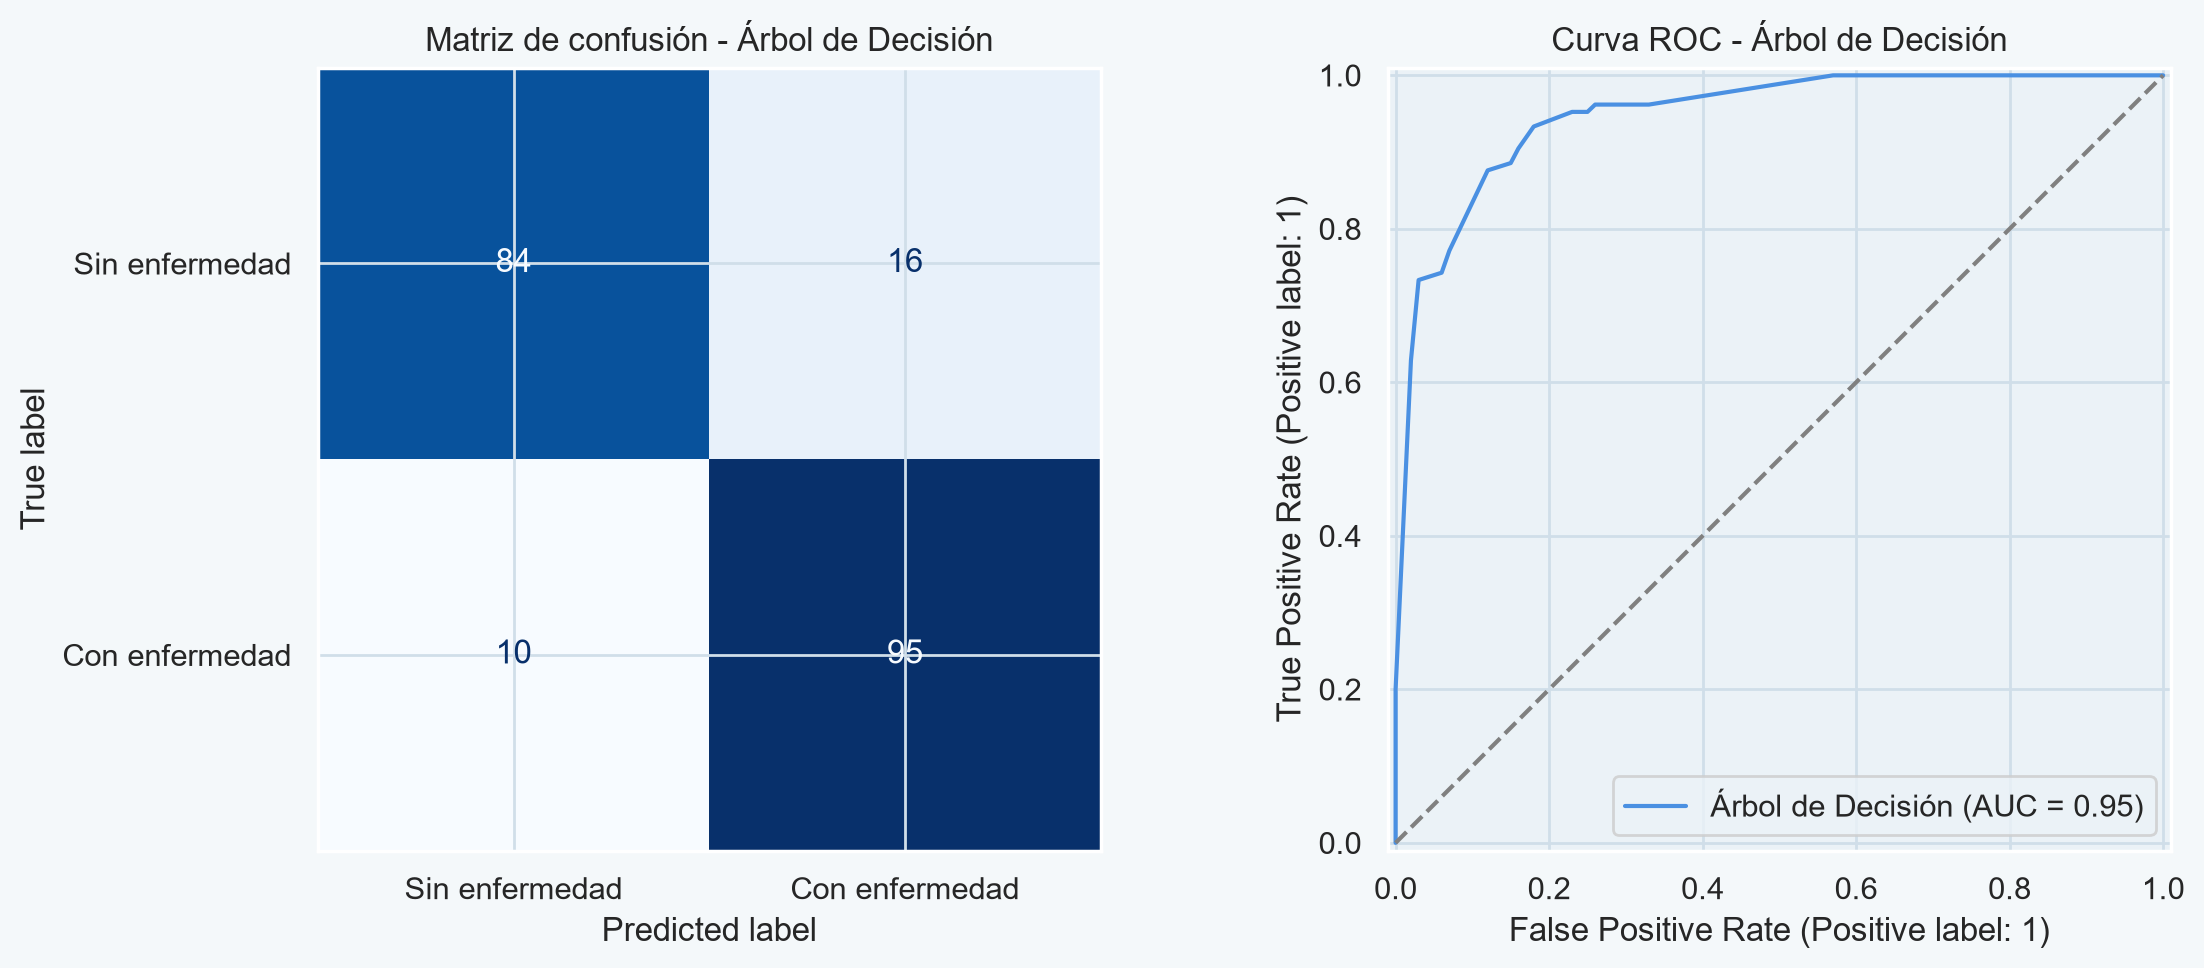

In [33]:
visualizar_resultados(mejor_dt, X_test, y_test, 'Árbol de Decisión')

## **5.2 Evaluación del modelo de RandomForest**

Finalmente, se evalúa el rendimiento del modelo tanto en el conjunto de datos de entrenamiento como en el de prueba:

In [34]:
# Evaluar el modelo optimizado en los datos de entrenamiento
print(classification_report(y_train, mejor_rf.predict(X_train)))

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       399
           1       0.88      0.93      0.90       421

    accuracy                           0.90       820
   macro avg       0.90      0.90      0.90       820
weighted avg       0.90      0.90      0.90       820



In [35]:
# Evaluar el modelo optimizado en los datos de prueba
print(classification_report(y_test, mejor_rf.predict(X_test)))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84       100
           1       0.83      0.90      0.86       105

    accuracy                           0.85       205
   macro avg       0.86      0.85      0.85       205
weighted avg       0.86      0.85      0.85       205



El rendimiento similar del modelo de RF tanto en los datos de entrenamiento como en los de prueba sugiere que no presenta sobreajuste (*overfitting*).

##### **Matriz de Confusión y Curva ROC-AUC**

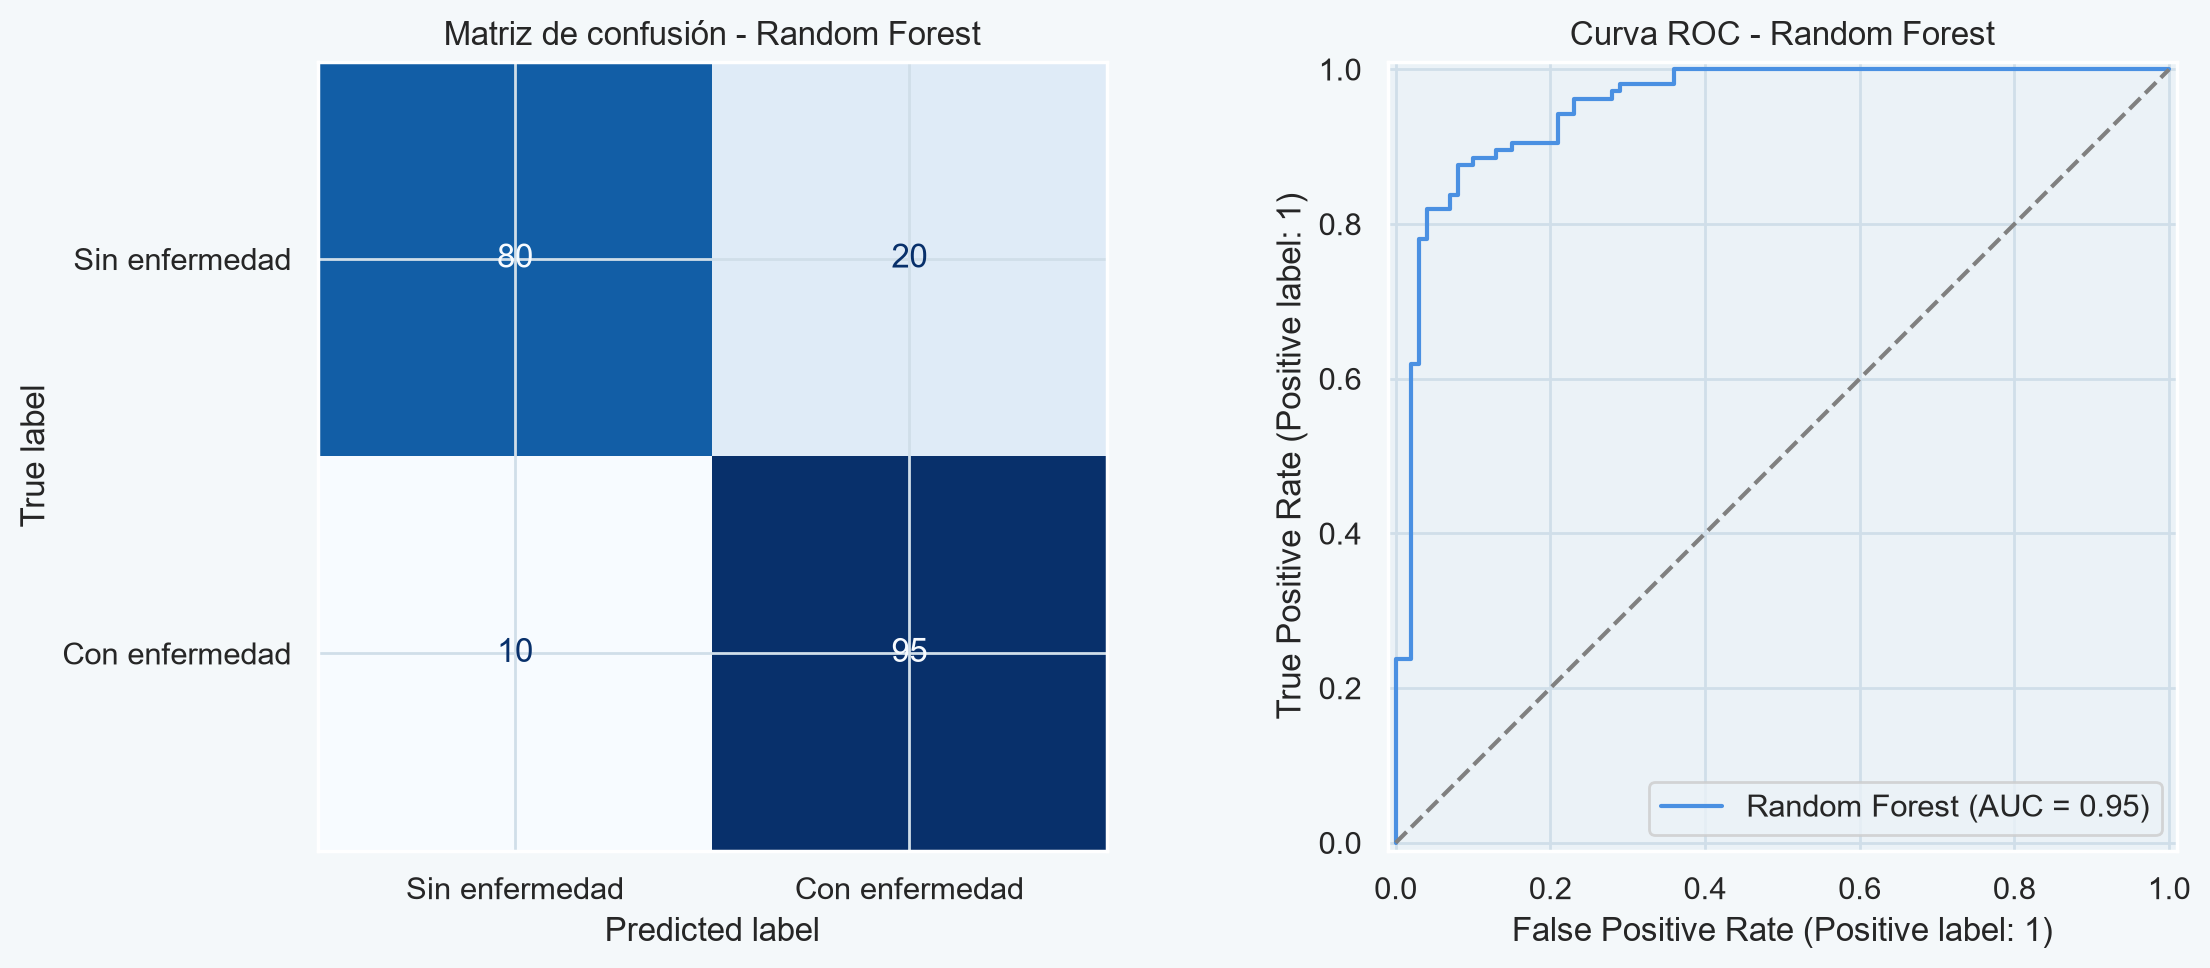

In [36]:
visualizar_resultados(mejor_rf, X_test, y_test, 'Random Forest')

## **5.3 Comparación del Rendimiento**

In [ ]:
# Modelos optimizados
modelos = {
    'Decision Tree': mejor_dt,
    'Random Forest': mejor_rf,
}

resultados = []

for nombre, modelo in modelos.items():

    # Predicciones
    y_pred = modelo.predict(X_test)

    # Obtener probabilidades de la clase positiva
    scores = modelo.predict_proba(X_test)[:, 1]

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Guardar métricas
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, scores),
        'Falsos negativos': fn
    })

# Crear tabla comparativa
tabla_comparativa = pd.DataFrame(resultados).set_index('Modelo')

display(tabla_comparativa.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Falsos negativos
Modelo,,,,,,
Decision Tree,0.873,0.856,0.905,0.880,0.948,10
Random Forest,0.854,0.826,0.905,0.864,0.953,10


## **5.4 Interpretación y Selección del Modelo**

El modelo **Random Forest** obtuvo un Recall de **0.905** para la clase 1 en el conjunto de prueba, identificando correctamente el **90,5 %** de los casos positivos. Este resultado es especialmente importante para el objetivo del proyecto, ya que permite reducir la cantidad de falsos negativos.

Además, obtuvo un F1-score de **0.864** y una Precision de **0.826**, lo que muestra un equilibrio entre la detección de casos positivos y la reducción de falsos positivos. Por su parte, el ROC-AUC de **0.953** refleja su alta capacidad para distinguir entre ambas clases.

Considerando estos resultados y su rendimiento durante la validación cruzada, se selecciona Random Forest como el modelo con mejor desempeño para el objetivo planteado.